# Analysis Notebook

In [214]:
import sys
sys.path.insert(0, "..")

import numpy as np
import matplotlib.pyplot as plt
from sampler.reader import ObservationReader, ReflectionReader

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams.update({
    "font.family": "serif"
})

In [215]:
### Point to simulated data
data_path = '../simulated_data/andromeda_data/case_3'
yaml_path = '../misc/basisconfigs/case3_poly.yaml'
chains_path = '../chains/andromeda_chains/case3/case3poly.npz'

In [216]:
import yaml
# Read from .yaml
with open(yaml_path) as f:
    basis_config = yaml.safe_load(f)

print(basis_config)

{'gainsBasis': {'nTimeModes': 7, 'nFreqModes': 7, 'basisFunction': 'polynomial'}, 'uncBasis': {'nTimeModes': 5, 'nFreqModes': 5, 'basisFunction': 'polynomial'}, 'cosBasis': {'nTimeModes': 5, 'nFreqModes': 5, 'basisFunction': 'polynomial'}, 'sinBasis': {'nTimeModes': 5, 'nFreqModes': 5, 'basisFunction': 'polynomial'}, 'rxBasis': {'nTimeModes': 5, 'nFreqModes': 5, 'basisFunction': 'polynomial'}, 'ambientBasis': {'nTimeModes': 6, 'basisFunction': 'polynomial', 'sources': ['internal_load', 'long_open', 'long_short', 'short', 'open']}, 'heatedBasis': {'nTimeModes': 6, 'basisFunction': 'polynomial', 'sources': ['heated_load']}, 'antennaBasis': {'nTimeModes': 1, 'nFreqModes': 1, 'basisFunction': 'polynomial', 'sources': ['antenna']}}


## Set up observation and reflections

In [217]:

observation = ObservationReader(f'{data_path}/sim_data.hdf5')
print(np.unique(observation.states_array))

reflection_dict = {'antenna':f'{data_path}/antenna_gamma_src.s2p',
                   'heated_load':f'{data_path}/heated_load_gamma_src.s2p',
                   'internal_load':f'{data_path}/internal_load_gamma_src.s2p',
                   'long_open':f'{data_path}/long_open_gamma_src.s2p',
                   'long_short':f'{data_path}/long_short_gamma_src.s2p',
                   'open':f'{data_path}/open_gamma_src.s2p',
                   'short':f'{data_path}/short_gamma_src.s2p',
                   'receiver':f'{data_path}/gamma_rec.s2p',
                   'noise_diode':f'{data_path}/noise_diode_gamma_src.s2p'}

reflections = ReflectionReader(component_dict=reflection_dict,
                               output_frequencies=observation.freqs,
                               polynomial_interp=True,
                               polynomial_fitting_order=10)

Calculated... delta_nu: 19531.25, delta_t: 5.0
['antenna' 'heated_load' 'internal_load' 'long_open' 'long_short' 'open'
 'short']


/Users/user/Desktop/RHINO/rhino-cal/notebooks/../sampler/reader.py:158: RankWarning: Polyfit may be poorly conditioned
  polyfit = np.polyfit(x=freq,
/Users/user/Desktop/RHINO/rhino-cal/notebooks/../sampler/reader.py:158: RankWarning: Polyfit may be poorly conditioned
  polyfit = np.polyfit(x=freq,
/Users/user/Desktop/RHINO/rhino-cal/notebooks/../sampler/reader.py:158: RankWarning: Polyfit may be poorly conditioned
  polyfit = np.polyfit(x=freq,
/Users/user/Desktop/RHINO/rhino-cal/notebooks/../sampler/reader.py:158: RankWarning: Polyfit may be poorly conditioned
  polyfit = np.polyfit(x=freq,
/Users/user/Desktop/RHINO/rhino-cal/notebooks/../sampler/reader.py:158: RankWarning: Polyfit may be poorly conditioned
  polyfit = np.polyfit(x=freq,
/Users/user/Desktop/RHINO/rhino-cal/notebooks/../sampler/reader.py:158: RankWarning: Polyfit may be poorly conditioned
  polyfit = np.polyfit(x=freq,
/Users/user/Desktop/RHINO/rhino-cal/notebooks/../sampler/reader.py:158: RankWarning: Polyfit may be 

# Check Observation

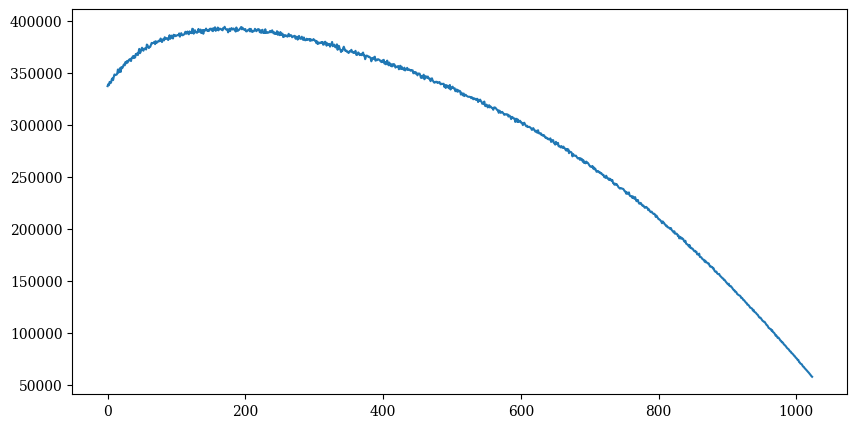

In [218]:
plt.plot(observation.data_waterfall[100])
plt.show()

## Set up basis functions

Set up the basis functions from the .yaml file

In [219]:
from sampler.linear_basis import BasisConstructor


In [220]:

gains_basis = BasisConstructor(observation.times,
                            observation.freqs,
                            n_time_modes=basis_config['gainsBasis']['nTimeModes'],
                            n_freq_modes=basis_config['gainsBasis']['nFreqModes'],
                            basis_function=basis_config['gainsBasis']['basisFunction'],
                            time_norm=1*(observation.times[-1] - observation.times[0]),
                            frequency_norm=np.median(observation.freqs),
                            zero_time=True)

unc_basis = BasisConstructor(observation.times,
                            observation.freqs,
                            n_time_modes=basis_config['uncBasis']['nTimeModes'],
                            n_freq_modes=basis_config['uncBasis']['nFreqModes'],
                            basis_function=basis_config['uncBasis']['basisFunction'],
                            time_norm=1*(observation.times[-1] - observation.times[0]),
                            frequency_norm=np.median(observation.freqs),
                            zero_time=True)

cos_basis = BasisConstructor(observation.times,
                            observation.freqs,
                            n_time_modes=basis_config['cosBasis']['nTimeModes'],
                            n_freq_modes=basis_config['cosBasis']['nFreqModes'],
                            basis_function=basis_config['cosBasis']['basisFunction'],
                            time_norm=1*(observation.times[-1] - observation.times[0]),
                            frequency_norm=np.median(observation.freqs),
                            zero_time=True)

sin_basis = BasisConstructor(observation.times,
                            observation.freqs,
                            n_time_modes=basis_config['sinBasis']['nTimeModes'],
                            n_freq_modes=basis_config['sinBasis']['nFreqModes'],
                            basis_function=basis_config['sinBasis']['basisFunction'],
                            time_norm=1*(observation.times[-1] - observation.times[0]),
                            frequency_norm=np.median(observation.freqs),
                            zero_time=True)

rx_basis = BasisConstructor(observation.times,
                            observation.freqs,
                            n_time_modes=basis_config['rxBasis']['nTimeModes'],
                            n_freq_modes=basis_config['rxBasis']['nFreqModes'],
                            basis_function=basis_config['rxBasis']['basisFunction'],
                            time_norm=1*(observation.times[-1] - observation.times[0]),
                            frequency_norm=np.median(observation.freqs),
                            zero_time=True)


# Set up thermal bases
# cal temperature set up: give the same time orders
# cal_n_time_modes = 6


ambient_basis = BasisConstructor(observation.times,
                            observation.freqs,
                            n_time_modes=basis_config['ambientBasis']['nTimeModes'],
                            n_freq_modes=1,
                            basis_function=basis_config['ambientBasis']['basisFunction'],
                            time_norm=1*(observation.times[-1] - observation.times[0]),
                            frequency_norm=np.median(observation.freqs),
                            zero_time=True)

ambient_basis_y = BasisConstructor(observation.times,
                            0,
                            n_time_modes=basis_config['ambientBasis']['nTimeModes'],
                            n_freq_modes=1,
                            basis_function=basis_config['ambientBasis']['basisFunction'],
                            time_norm=1*(observation.times[-1] - observation.times[0]),
                            frequency_norm=np.median(observation.freqs),
                            zero_time=True)

heated_basis = BasisConstructor(observation.times,
                            observation.freqs,
                            n_time_modes=basis_config['heatedBasis']['nTimeModes'],
                            n_freq_modes=1,
                            basis_function=basis_config['heatedBasis']['basisFunction'],
                            time_norm=1*(observation.times[-1] - observation.times[0]),
                            frequency_norm=np.median(observation.freqs),
                            zero_time=True)

heated_basis_y = BasisConstructor(observation.times,
                            0,
                            n_time_modes=basis_config['heatedBasis']['nTimeModes'],
                            n_freq_modes=1,
                            basis_function=basis_config['heatedBasis']['basisFunction'],
                            time_norm=1*(observation.times[-1] - observation.times[0]),
                            frequency_norm=np.median(observation.freqs),
                            zero_time=True)
####

antenna_basis = BasisConstructor(observation.times,
                            observation.freqs,
                            n_time_modes=basis_config['antennaBasis']['nTimeModes'],
                            n_freq_modes=basis_config['antennaBasis']['nFreqModes'],
                            basis_function=basis_config['antennaBasis']['basisFunction'],
                            time_norm=1*(observation.times[-1] - observation.times[0]),
                            frequency_norm=np.median(observation.freqs),
                            zero_time=True)

/Users/user/Desktop/RHINO/rhino-cal/notebooks/../sampler/linear_basis.py:246: RuntimeWarning: invalid value encountered in scalar divide
  return 2.0 * (array - array_min) / (array_max - array_min) - 1.0


## Construct Operators

In [221]:
from sampler.operator_setup import generate_noise_wave_transfer_matrix
from sampler.operator_setup import generate_non_smooth_source_matrix, generate_smooth_source_matrix, generate_noise_wave_transfer_matrix
# Noise Wave Operator
X_noise_wave, nw_slice_dict = generate_noise_wave_transfer_matrix(observation,
                                                               reflections,
                                                               unc_basis,
                                                               cos_basis,
                                                               sin_basis,
                                                               rx_basis)
print(nw_slice_dict)
print(X_noise_wave.shape)


{'unc': slice(0, 25, None), 'cos': slice(25, 50, None), 'sin': slice(50, 75, None), 'rx': slice(75, 100, None)}
(4423680, 100)


## Construct Antenna Operator

In [222]:
X_antenna = generate_smooth_source_matrix(observation,
                                          reflections,
                                          source_basis=antenna_basis,
                                          source_label='antenna')

# X_noise_diode = generate_smooth_source_matrix(observation,
#                                           reflections,
#                                           source_basis=noise_diode_basis,
#                                           source_label='noise_diode')

print(X_antenna.shape)

(4423680, 1)


### Combine Noisewave and Antenna Operators

In [223]:
from sampler.operator_setup import concat_and_index_operators

X_ant_noisewave = np.concatenate((X_antenna, X_noise_wave), axis=1)

X_ant_noisewave, ant_noise_wave_slice_dict = concat_and_index_operators([X_antenna,
                                                                         #X_noise_diode,
                                                                         X_noise_wave],
                                                                         label_list=['antenna',
                                                                                     #'noise_diode',
                                                                                     'noise_wave'])

print(ant_noise_wave_slice_dict)

{'antenna': slice(0, 1, None), 'noise_wave': slice(1, 101, None)}


## Construct Calibration Source Operator

In [224]:
print(np.unique(observation.switch_states))

['antenna' 'heated_load' 'internal_load' 'long_open' 'long_short' 'open'
 'short']


In [225]:
X_ambient = generate_smooth_source_matrix(observation, reflections,
                                          source_basis=ambient_basis,
                                          source_label=['internal_load', 'long_open',
                                                        'long_short', 'open', 'short'])
X_heated = generate_smooth_source_matrix(observation, reflections,
                                         source_basis=heated_basis,
                                         source_label='heated_load')

X_calibrator, calibrator_slice_dict = concat_and_index_operators([X_ambient,
                                                                  X_heated],
                                                                  ['ambient',
                                                                   'heated'])


from sampler.priors import generate_smooth_thermistor_operator_matrix

Y_ambient = generate_smooth_thermistor_operator_matrix(observation,
                                          source_basis=ambient_basis_y,
                                          source_label=['internal_load', 'long_open',
                                                        'long_short', 'open', 'short'])


Y_heated = generate_smooth_thermistor_operator_matrix(observation,
                                         source_basis=heated_basis_y,
                                         source_label='heated_load')

Y_calibrator, calibrator_slice_dict_y = concat_and_index_operators([Y_ambient,
                                                                  Y_heated],
                                                                  ['ambient',
                                                                   'heated'])

In [226]:

# plt.pcolormesh(X_calibrator)
# plt.show()

# plt.pcolormesh(Y_calibrator)
# plt.show()

print(calibrator_slice_dict)

cont = X_calibrator @ np.ones_like(X_calibrator[0])
cont = np.reshape(cont, shape=observation.data_waterfall.shape)
# plt.pcolormesh(cont)
# plt.show()

{'ambient': slice(0, 6, None), 'heated': slice(6, 12, None)}


In [227]:
print(np.unique(observation.switch_states))

['antenna' 'heated_load' 'internal_load' 'long_open' 'long_short' 'open'
 'short']


### Construct Cal Source Priors

In [228]:
from sampler.priors import setup_probe_cal_priors
cal_source_priors, cal_source_prior_inv_cov = setup_probe_cal_priors(observation,
                                           source_temp_dict={'heated':'heated_load',
                                                             'ambient':['internal_load',
                                                                        'open',
                                                                        'short',
                                                                        'long_open',
                                                                        'long_short']},
                                                                        temp_std=0.01)


In [229]:
### Attempt a Weiner solution fit

from sampler.gibbs_sample import construct_gcr_lhs, construct_gcr_rhs, solve_gcr



cal_source_lhs = construct_gcr_lhs(linear_operator=Y_calibrator,
                                   inv_data_cov=cal_source_prior_inv_cov,
                                   inv_prior_cov=None,)
cal_source_rhs = construct_gcr_rhs(linear_operator=Y_calibrator,
                                   data=cal_source_priors,
                                   inv_data_cov=cal_source_prior_inv_cov,
                                   omega_data=np.zeros_like(cal_source_priors),
                                   priors=None,
                                   inv_prior_cov=None,
                                   weiner_solution=True,)

init_calibrator_solution = solve_gcr(cal_source_lhs, cal_source_rhs,linalg_init=False,
                                     atol=1e-10, rtol=1e-12, maxiter=int(1e6))


print(init_calibrator_solution)


# ambient_amps, heated_amps = init_calibrator_solution[:4], init_calibrator_solution[4:]
# print(ambient_amps)
# print(heated_amps)

# reconstructed_ambient = ambient_basis.basis_matrix @ ambient_amps
# reconstructed_heated = ambient_basis.basis_matrix @ heated_amps

# plt.pcolormesh(np.reshape(reconstructed_ambient, shape=observation.data_waterfall.shape))
# plt.colorbar()
# plt.show()

# plt.pcolormesh(np.reshape(reconstructed_heated, shape=observation.data_waterfall.shape))
# plt.colorbar()
# plt.show()

[ 8.38372725e-03  2.00609537e-03 -1.70756454e+01  3.13465843e+00
  1.30864348e+01  2.91431353e+02  1.74211938e-03 -1.91012138e-03
  3.12177962e-01 -8.71957748e-01 -4.99099397e-02  3.93436943e+02]


In [230]:
# cal_source_priors = np.array([np.mean(observation.temperatures['ambient']),
#                                      np.mean(observation.temperatures['heated'])])
# cal_source_prior_inv_cov = np.ones_like(cal_source_priors) * (1 / 0.0005)

print(cal_source_prior_inv_cov)

[    0.     0.     0. ... 10000. 10000. 10000.]


In [231]:
## Construct cal source priors from raw temperatures

## Gain Operator

In [232]:
U_gain = gains_basis.basis_matrix
print(U_gain.shape)
# plt.pcolormesh(U_gain)
# plt.show()

(4423680, 49)


In [233]:
print(observation.temperatures)

{'heated': array([392.29226436, 392.32579986, 392.31568583, ..., 392.83450919,
       392.81707249, 392.83299795], shape=(4320,)), 'ambient': array([298.55146095, 298.51802797, 298.5013742 , ..., 290.61416722,
       290.59603742, 290.58612891], shape=(4320,))}


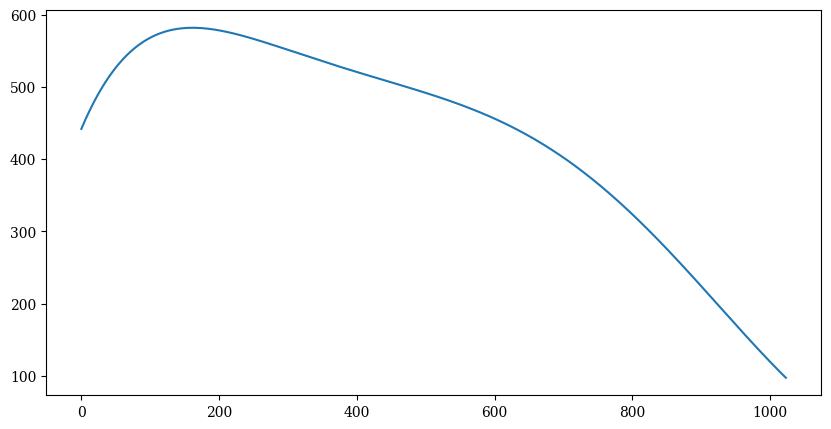

In [234]:
# get an initial guess of the gains params

def init_gain_guess(observation_obj: ObservationReader,
                    reflections_obj: ReflectionReader,
                    gains_basis: BasisConstructor,
                    noise_source_label: str = "heated_load",
                    load_label: str = 'internal_load',
                    noise_source_temp: int | None = None):

    noise_source_mask = (observation_obj.states_array == noise_source_label)
    load_mask = (observation_obj.states_array == load_label)
    p_ns = observation_obj.data_waterfall[noise_source_mask].mean(axis=0)
    p_l = observation_obj.data_waterfall[load_mask].mean(axis=0)

    if noise_source_temp is not None: t_ns = noise_source_temp
    else:
        t_ns = np.mean(observation_obj.temperatures['heated'])
    t_l = np.mean(observation_obj.temperatures['ambient'])

    gamma_rec = reflections_obj.s11_dict['receiver']

    mean_gain = (p_ns - p_l) / ((t_ns - t_l) * (1 - np.power(np.abs(gamma_rec), 2)))

    fitting_gain = np.zeros_like(observation.data_waterfall)
    fitting_gain[:,:] = mean_gain
    fitting_gain = fitting_gain.flatten()
    init_amp_guess = np.linalg.lstsq(gains_basis.basis_matrix, fitting_gain)[0]

    return init_amp_guess


# def gain_correction(observation_obj: ObservationReader,
#                     reflections_obj: ReflectionReader,
#                     noise_source_label: str = "heated_load",
#                     load_label: str = 'internal_load',
#                     polynomial_order: int,
#                     noise_source_temp: int | None = None,):
    
#     noise_source_mask = (observation_obj.states_array == noise_source_label)
#     load_mask = (observation_obj.states_array == load_label)
#     p_ns = observation_obj.data_waterfall[noise_source_mask].mean(axis=0)
#     p_l = observation_obj.data_waterfall[load_mask].mean(axis=0)
    


init_gain_amps = init_gain_guess(observation, reflections, gains_basis)

recov_init_gains = gains_basis.basis_matrix @ init_gain_amps
recov_init_gains = np.reshape(recov_init_gains,
                              shape=observation.data_waterfall.shape)

plt.plot(np.mean(recov_init_gains, axis=0))

# Set up Gibbs Sampler

In [235]:
# from sampler.gibbs_sample import sample_loop
# from sampler.gibbs_sample import GibbsSampleParams

def plot_chains_and_auto_correlation(ant_nw_chains,
                                     cal_chains,
                                     gain_chains,
                                     c_ant_nw='red',
                                     c_cal='blue',
                                     c_gain='green',
                                     alpha=0.25,
                                     figsize=(10,8),
                                     auto_lim=50):
    """ 
    Plot chains
    """
    n_samps = len(ant_nw_chains[:,0])
    samples = np.arange(n_samps)

    fig, axes = plt.subplots(
        nrows=3,
        ncols=2,
        sharex='col',
        layout='constrained',
        figsize=figsize,
    )

    def _plotchain(axis, chain, c, auto_axis):
        chain_min, chain_max = np.min(chain), np.max(chain)
        scaled_chain = 2.0 * (chain - chain_min) / (chain_max - chain_min) - 1.0
        axis.plot(samples, scaled_chain, c=c, alpha=alpha)

        auto_chain = np.correlate((chain / chain.mean())-1, (chain / chain.mean())-1, mode='full')
        auto_chain = auto_chain[auto_chain.size // 2:]
        auto_axis.plot(auto_chain[:auto_lim] / np.max(auto_chain[:auto_lim]), c=c, alpha=alpha)


    
    # ant_nw
    n_params = len(ant_nw_chains[0])
    for i in range(n_params):

        _plotchain(axes[0,0], ant_nw_chains[:,i],c_ant_nw, axes[0,1])

    # gains
    n_params = len(gain_chains[0])
    for i in range(n_params):
        _plotchain(axes[1,0], gain_chains[:,i], c_gain, axes[1,1])
    # cal
    n_params = len(cal_chains[0])
    for i in range(n_params):
        _plotchain(axes[2,0], cal_chains[:,i], c_cal, axes[2,1])

    ###
    axes[0,0].set_ylabel('Antenna and \n Noise Wave')
    axes[1,0].set_ylabel('Gain')
    axes[2,0].set_ylabel('Calibrators')
    fig.supylabel('Scaled Chains')

    axes[2,0].set_xlabel('Sample')
    axes[2,1].set_xlabel('Sample Lag')

    auto_axes = [axes[i,1] for i in range(3)]
    axes[1,1].set_ylabel('Chain Autocorrelation')

    plt.show()



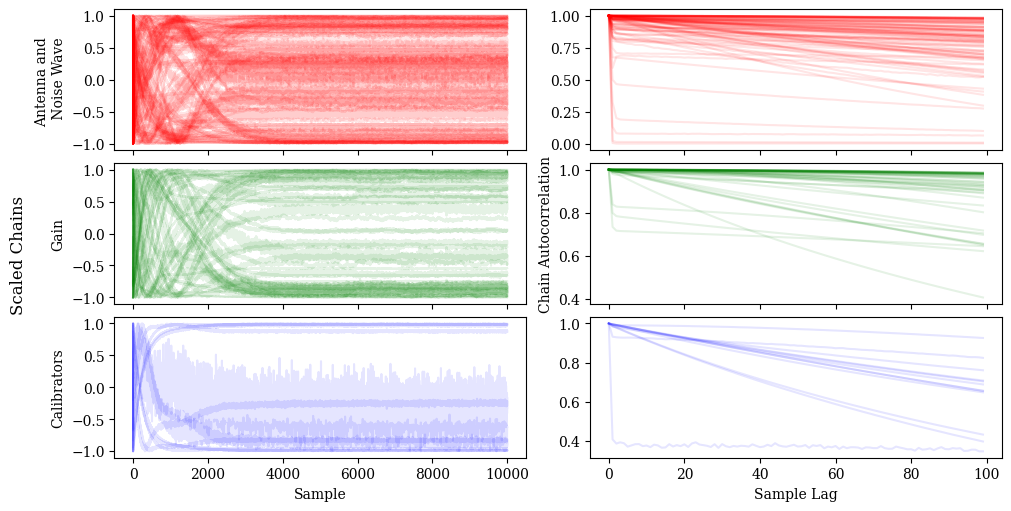

In [236]:

param_dict = np.load(chains_path, allow_pickle=True)
plot_chains_and_auto_correlation(ant_nw_chains=param_dict['all_p_ant_nw'],
            gain_chains=param_dict['all_p_gain'],
            cal_chains=param_dict['all_p_cal_src'],
            alpha=0.1,
            auto_lim=100,
            figsize=(10,5))


NpzFile '../chains/andromeda_chains/case3/case3poly.npz' with keys: all_p_cal_src, all_p_gain, all_p_ant_nw, all_chi_squared_stats


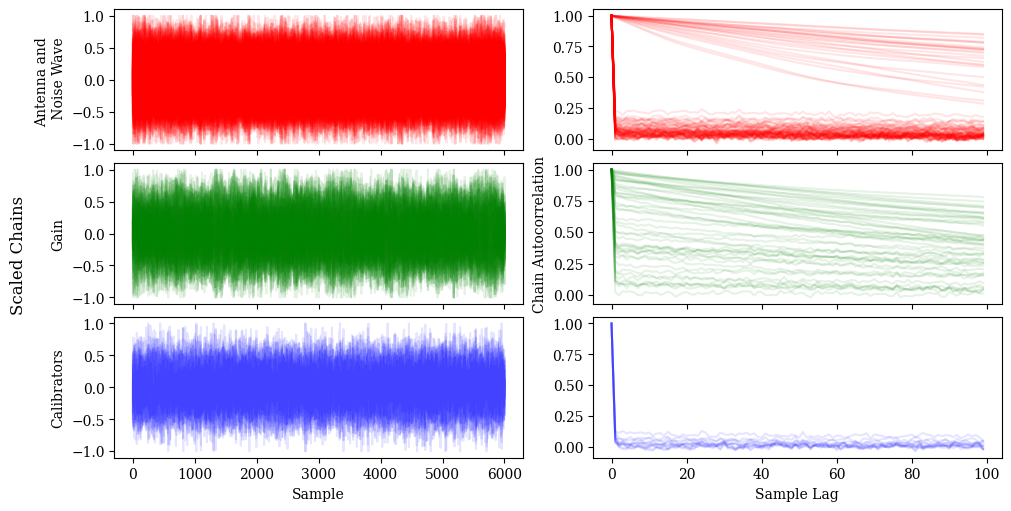

In [237]:
n_to_discard = 4000

print(param_dict)
new_param_dict = {
    "all_p_cal_src":param_dict['all_p_cal_src'],
    "all_p_gain":param_dict['all_p_gain'],
    "all_p_ant_nw":param_dict['all_p_ant_nw'],
    }

param_dict = new_param_dict

param_dict['all_p_cal_src'] = param_dict['all_p_cal_src'][n_to_discard:]
param_dict['all_p_gain'] = param_dict['all_p_gain'][n_to_discard:]
param_dict['all_p_ant_nw'] = param_dict['all_p_ant_nw'][n_to_discard:]

plot_chains_and_auto_correlation(ant_nw_chains=param_dict['all_p_ant_nw'],
            gain_chains=param_dict['all_p_gain'],
            cal_chains=param_dict['all_p_cal_src'],
            alpha=0.1,
            auto_lim=100,
            figsize=(10,5))

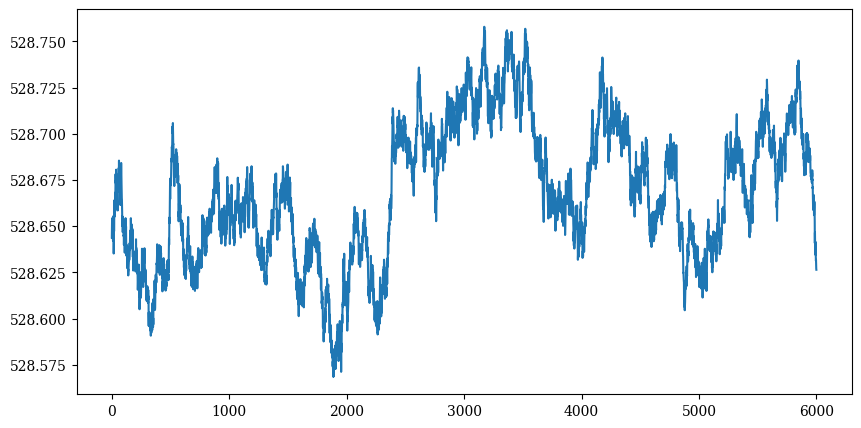

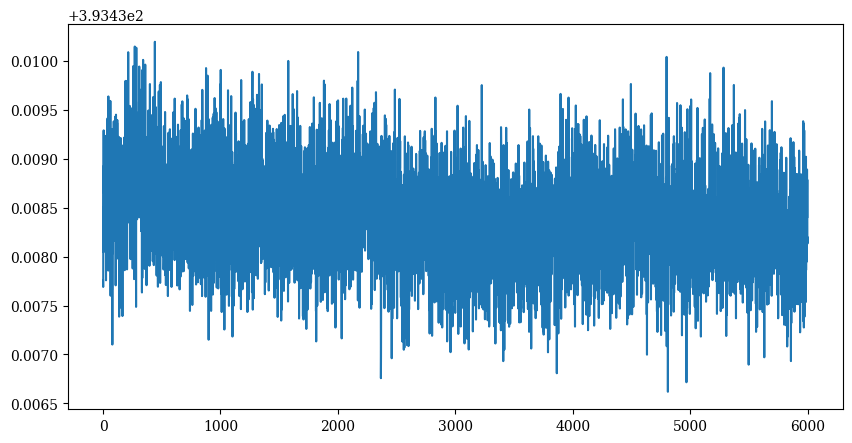

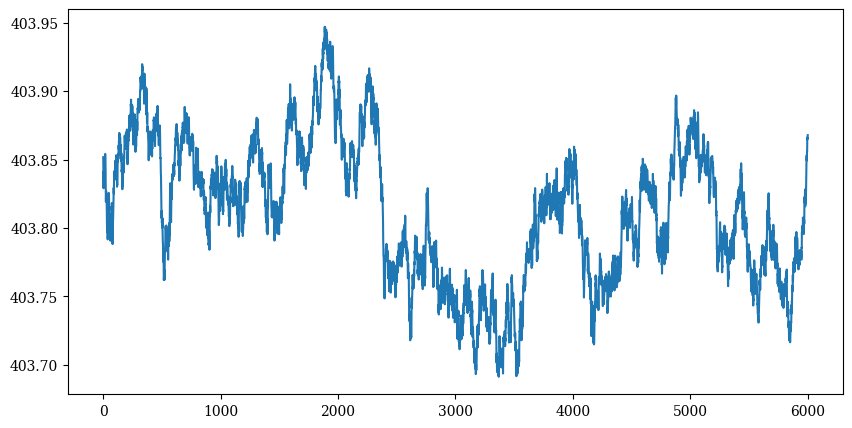

393.43840588483005


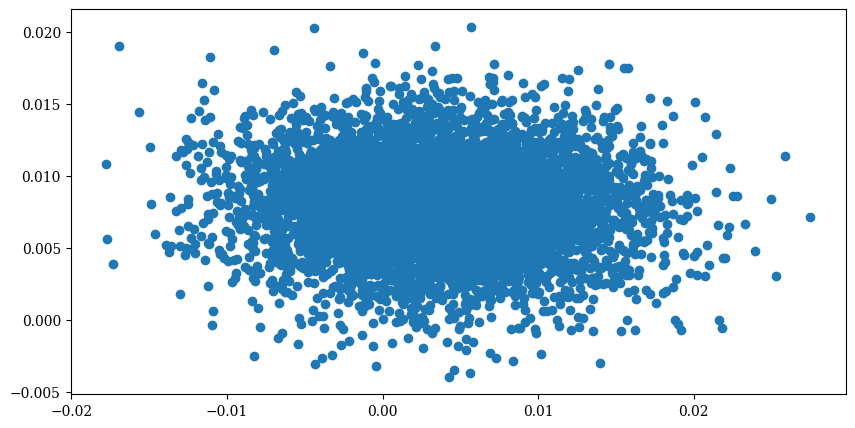

In [238]:
plt.plot(param_dict['all_p_gain'][:,-1])
plt.show()
plt.plot(param_dict['all_p_cal_src'][:, -1])
plt.show()
plt.plot(param_dict['all_p_ant_nw'][:, -1])
plt.show()

print(np.mean(param_dict['all_p_cal_src'][:, -1]))

plt.scatter(param_dict['all_p_cal_src'][:, 0], param_dict['all_p_cal_src'][:, 1])
plt.show()



In [239]:
import h5py
sim_filepath = f'{data_path}/sim_data.hdf5_sim'
with h5py.File(sim_filepath) as f:
    t_unc_sim = f['t_unc'][()]
    t_sin_sim = f['t_sin'][()]
    t_cos_sim = f['t_cos'][()]
    t_rx_sim = f['t_0'][()]
    gain_sim = f['gains'][()]
    t_amb_sim = f['t_src_open'][()]
    t_heated_sim = f['t_src_heated_load'][()]


## Calibrator Recovery

In [240]:
def plot_calibrator_temperatures(observation_obj:ObservationReader,
                                 ambient_chains,
                                 ambient_basis,
                                 heated_chains,
                                 heated_basis,
                                 true_ambient,
                                 true_heated,
                                 figsize=(6,10),
                                 resid_lims=0.01,
                                 alpha_lines=0.4,
                                 ):

    def plot_bounds(basis,
                    amps,
                    fig,
                    full_ax,
                    resid_ax,
                    color,
                    c_true,
                    c_measured,
                    alpha,
                    measured_tod,
                    true_temperatures,
                    ):
        
        def reproduce_tod(amps):
            rec = basis @ amps
            return rec

        recovered_tod = np.array([reproduce_tod(a) for a in amps])
        med_rec = np.quantile(recovered_tod,
                                          0.5, axis=0)
        sigma_bounds = [
             np.quantile(recovered_tod, 0.5-(0.68/2), axis=0),
             np.quantile(recovered_tod, 0.5+(0.68/2), axis=0)
                    ]
        three_sigma_bounds = [
            np.quantile(recovered_tod, 0.5-(0.997/2), axis=0),
            np.quantile(recovered_tod, 0.5+(0.997/2), axis=0),
            ]
        
        full_ax.plot(observation_obj.times, true_temperatures, c=c_true, label='True')
        full_ax.plot(observation_obj.times, med_rec, c=color, label='Max Prob.')
        
        full_ax.fill_between(observation_obj.times, sigma_bounds[0], sigma_bounds[-1],
                                     color=color, alpha=2*alpha, label=r'$1\,\sigma$')
        
        full_ax.fill_between(observation_obj.times, three_sigma_bounds[0], three_sigma_bounds[-1],
                             color=color, alpha=alpha, label=r'$3\,\sigma$')

        
        resid_ax.plot(observation_obj.times, med_rec - true_temperatures, c=color)
        resid_ax.fill_between(observation_obj.times, sigma_bounds[0]-true_temperatures,
                              sigma_bounds[-1]-true_temperatures,
                              color=color, alpha=2*alpha)
        resid_ax.fill_between(observation_obj.times, three_sigma_bounds[0]-true_temperatures,
                              three_sigma_bounds[-1]-true_temperatures,
                                                     color=color, alpha=alpha)
        
        resid_ax.plot(observation_obj.times, np.zeros_like(observation_obj.times), ls='--', c='black')
        # resid_ax.scatter(observation_obj.times, np.zeros_like(observation_obj.times), c='black')

        # resid_ax.plot(observation.times, measured_tod - true_temperatures, ls='dotted', c='grey',
        #               alpha=0.25)

        resid_ax.scatter(observation.times, measured_tod - true_temperatures, c='grey',
                              alpha=0.1)

        # full_ax.plot(observation_obj.temperature_times, measured_tod, c=c_measured,
        #              label='Measured', ls='dotted')
        
        full_ax.scatter(observation.times, measured_tod, c='grey',
                                      alpha=0.1)

    fig, axes = plt.subplots(nrows=3, ncols=1, layout='constrained', sharex=True,
                             figsize=figsize)

    plot_bounds(basis=ambient_basis,
                amps=ambient_chains,
                fig=fig,
                full_ax=axes[0],
                resid_ax=axes[2],
                color='blue',
                c_true='black',
                c_measured='black',
                alpha=alpha_lines,
                measured_tod=observation_obj.temperatures['ambient'],
                true_temperatures=true_ambient,
                )

    plot_bounds(basis=heated_basis,
                    amps=heated_chains,
                    fig=fig,
                    full_ax=axes[1],
                    resid_ax=axes[2],
                    color='red',
                    c_true='black',
                    c_measured='black',
                    alpha=alpha_lines,
                    measured_tod=observation_obj.temperatures['heated'],
                    true_temperatures=true_heated,
                    )

    axes[-1].set_ylim(-resid_lims, resid_lims)
    fig.supxlabel('Times [s]')
    axes[0].set_ylabel('Temperatures [K]')
    axes[1].set_ylabel('Residuals [K]')

    plt.show()

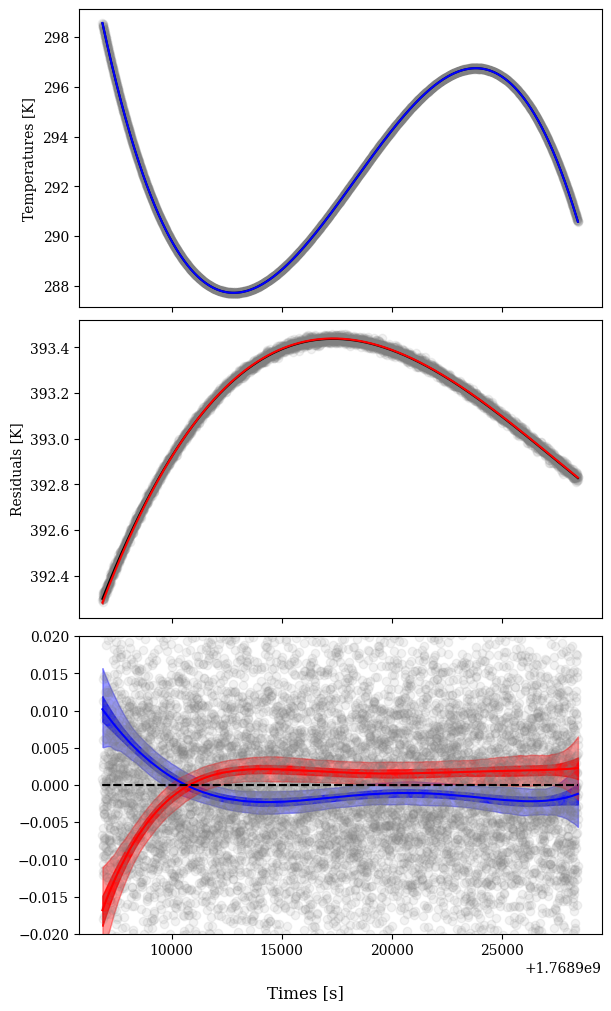

In [241]:
t_amb_chains = param_dict['all_p_cal_src'][:,calibrator_slice_dict_y['ambient']]
t_heated_chains = param_dict['all_p_cal_src'][:,calibrator_slice_dict_y['heated']]

plot_calibrator_temperatures(observation_obj=observation,
                                 ambient_chains=t_amb_chains,
                                 ambient_basis=ambient_basis_y.basis_matrix,
                                 heated_chains=t_heated_chains,
                                 heated_basis=heated_basis_y.basis_matrix,
                                 true_ambient=t_amb_sim,
                                 true_heated=t_heated_sim,
                                 resid_lims=0.02
                                 )



## Gain Recovery

[-2.22455893e+00 -8.48392650e+00  2.06806781e+01 -3.53979459e+00
 -9.09811218e+00  2.39589250e+00  3.95588206e-01 -1.28937956e+00
  5.39180116e+00 -5.48770184e+00 -1.10914931e+00  3.19924485e+00
 -6.53859327e-01 -2.25918414e-01  1.49688045e+00  6.27942971e+00
 -1.39985380e+01  4.59127773e+00  3.97209187e+00 -3.56278357e+00
  1.05271651e+00  1.49775524e+01 -2.92437352e+01 -8.04051610e+00
  1.45657261e+01  5.36591023e+01  1.73911065e+02 -2.53506071e+02
 -4.89193449e+00 -8.32963393e+00  2.57034708e+01  4.67251411e+00
  2.11736588e+01  2.13299884e+01 -7.59027845e+01 -7.73074631e+00
  2.25828030e+01 -5.31620443e+00 -1.10197424e+01 -4.65880528e+01
 -1.35443668e+02  2.14511063e+02  7.01016594e-01  4.48766826e+01
 -6.21102359e+01 -4.83940448e+01 -1.50033317e+02 -2.13125959e+02
  5.28665855e+02]


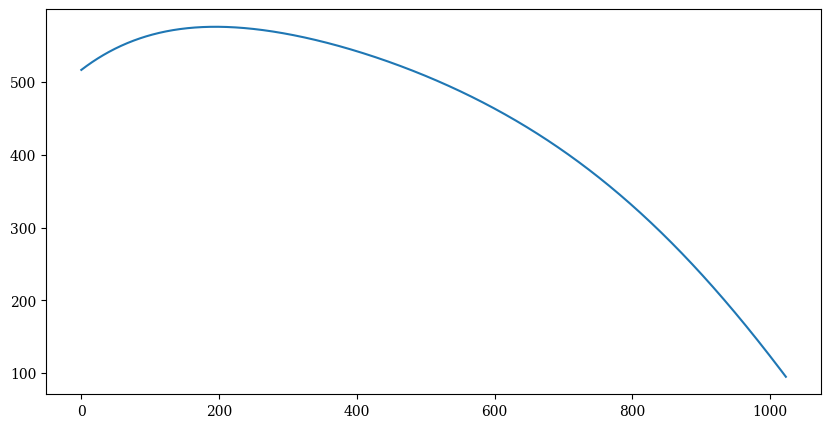

In [242]:
median_gains = np.median(param_dict['all_p_gain'], axis=0)
mean_gains = np.mean(param_dict['all_p_gain'], axis=0)
print(median_gains)

reconstructed_gains = gains_basis.basis_matrix @ median_gains

reconstructed_gains = np.reshape(reconstructed_gains, shape=observation.data_waterfall.shape)

plt.plot(np.mean(reconstructed_gains, axis=0))
plt.show()

In [243]:
def compare_sim_and_recontructed(simulated_surface,
                                 basis_obj:BasisConstructor,
                                 amplitudes,
                                 times,
                                 freqs,
                                 cmap_rec='viridis',
                                 cmap_res='RdBu',
                                 perc_diff=False,
                                 surface_label='',
                                 residvminvmax=None,
                                 figsize=(10,8)):
    fig, (ax1, ax2, ax3) = plt.subplots(nrows=3, sharex=True, layout='constrained',
                                        figsize=figsize)

    recovered_surface = basis_obj.basis_matrix @ amplitudes
    recovered_surface = np.reshape(recovered_surface, shape=simulated_surface.shape)

    vmin = np.min(np.array([simulated_surface, recovered_surface]))
    vmax = np.max(np.array([simulated_surface, recovered_surface]))
    
    im1 = ax1.pcolormesh(freqs, times, simulated_surface, cmap=cmap_rec, vmin=vmin, vmax=vmax)
    ax1.set_title('True Simulated')

    im2 = ax2.pcolormesh(freqs, times, recovered_surface, cmap=cmap_rec, vmin=vmin, vmax=vmax)
    ax2.set_title('Recovered')

    if perc_diff:
        res = 200 * (recovered_surface - simulated_surface) / (recovered_surface+simulated_surface)
    else:
        res = recovered_surface - simulated_surface
    

    if residvminvmax is not None:
        im3 = ax3.pcolormesh(freqs, times, res, cmap=cmap_res,
                                 vmin=-residvminvmax,
                                 vmax=residvminvmax)
    else:
        im3 = ax3.pcolormesh(freqs, times, res, cmap=cmap_res)

    fig.colorbar(im1, ax=[ax1, ax2], label=surface_label)

    if perc_diff:
        res_label='% Difference'
    else:
        res_label='Residual [K]'
    fig.colorbar(im3, ax=ax3, label=res_label)

    fig.supxlabel('Freqs [Hz]')
    fig.supylabel('Time [s]')
    plt.show()
    

## Noise Wave Param Recovery

In [244]:
param_dict['all_p_ant_nw'][ant_noise_wave_slice_dict['noise_wave']]

mean_ant_nw = param_dict['all_p_ant_nw'].mean(axis=0)

median_ant_nw = np.mean(param_dict['all_p_ant_nw'], axis=0)

# print(ant_noise_wave_slice_dict['noise_wave'])

mean_nw = median_ant_nw[ant_noise_wave_slice_dict['noise_wave']]
print(nw_slice_dict)

mean_unc = mean_nw[nw_slice_dict['unc']]
mean_cos = mean_nw[nw_slice_dict['cos']]
mean_sin = mean_nw[nw_slice_dict['sin']]
mean_rx = mean_nw[nw_slice_dict['rx']]

print(mean_unc, mean_cos, mean_sin, mean_rx)

{'unc': slice(0, 25, None), 'cos': slice(25, 50, None), 'sin': slice(50, 75, None), 'rx': slice(75, 100, None)}
[ 1.40890630e+00 -6.45230405e-01 -1.07051812e+00  2.59387478e-01
  1.75748732e-01 -1.90401806e+00  7.65086526e-01  1.10046200e+00
 -1.25898293e-01 -4.81347498e-02 -7.58141829e-02  9.94811711e-02
 -2.87309073e+00  1.25917739e-01  1.13357917e+01  8.24672941e-01
 -3.11275628e-01 -9.94181366e+00  2.34591632e+00  3.46310492e+00
 -1.30713696e-01  1.63576182e-02 -3.96671713e+00 -5.69270839e+00
  3.02002471e+02] [  1.33690595  -0.6908564   -0.86137025   0.46743953   0.0585475
  -3.77243568   1.21772234   2.69118249  -0.60793629  -0.15143419
   0.18665468  -0.03777482   7.85169373  -0.29505078   2.41289114
   1.62939513  -0.4449639   -6.09046061  -3.43591442   4.61114522
  -0.14225701   0.03812826   0.49007186   0.25110618 -27.65984615] [-2.26614519e+00  4.95120814e-01  1.88818483e+00  1.09045639e-01
 -3.68417511e-01  1.47726885e+00 -5.80777432e-01 -1.19955005e+00
  1.40530595e-01  5.

In [245]:
figsize=(5,10)

In [246]:
# compare_sim_and_recontructed(gain_sim,
#                              gains_basis,
#                              mean_gains,
#                              observation.times,
#                              observation.freqs,
#                              surface_label='Gain',
#                              perc_diff=True,
#                              residvminvmax=0.1,
#                              figsize=figsize)

In [247]:
# figsize=(5,10)

# compare_sim_and_recontructed(t_unc_sim,
#                              unc_basis,
#                              mean_unc,
#                              observation.times,
#                              observation.freqs,
#                              perc_diff=True,
#                              residvminvmax=0.5,
#                              surface_label=r'$T_{\rm unc}$ [K]',
#                              figsize=figsize)
# compare_sim_and_recontructed(t_cos_sim,
#                              cos_basis,
#                              mean_cos,
#                              observation.times,
#                              observation.freqs,
#                              perc_diff=True,
#                              residvminvmax=0.5,
#                              surface_label=r'$T_{\rm cos}$ [K]',
#                              figsize=figsize)
# compare_sim_and_recontructed(t_sin_sim,
#                              sin_basis,
#                              mean_sin,
#                              observation.times,
#                              observation.freqs,
#                              perc_diff=True,
#                              residvminvmax=0.5,
#                              surface_label=r'$T_{\rm sin}$ [K]',
#                              figsize=figsize)
# compare_sim_and_recontructed(t_rx_sim,
#                              rx_basis,
#                              mean_rx,
#                              observation.times,
#                              observation.freqs,
#                              perc_diff=True,
#                              residvminvmax=0.5,
#                              surface_label=r'$T_{\rm rx}$ [K]',
#                              figsize=figsize)

In [248]:
def plot_corner(
    chains: np.ndarray,
    labels: list[str] | None = None,
    truths: list[float] | None = None,
    title: str | None = None,
    **corner_kwargs,
):
    """
    Plot posterior densities and parameter correlations using corner.py.

    Parameters
    ----------
    chains : np.ndarray
        Array of parameter chains with shape:
        (n_samples, n_parameters)

    labels : list[str], optional
        Names of the parameters.

    truths : list[float], optional
        True/reference values for each parameter.

    title : str, optional
        Optional figure title.

    **corner_kwargs
        Additional keyword arguments passed to corner.corner().

    Returns
    -------
    fig : matplotlib.figure.Figure
        The generated corner plot figure.
    """

    import corner
    chains = np.asarray(chains)

    if chains.ndim != 2:
        raise ValueError(
            f"chains must be 2D with shape (n_samples, n_parameters), "
            f"got shape {chains.shape}"
        )

    n_parameters = chains.shape[1]

    if labels is not None and len(labels) != n_parameters:
        raise ValueError(
            f"Expected {n_parameters} labels, got {len(labels)}"
        )

    if truths is not None and len(truths) != n_parameters:
        raise ValueError(
            f"Expected {n_parameters} truths, got {len(truths)}"
        )

    one_sigma_1d = 0.683
    q_lower = 1 / 2 - one_sigma_1d / 2
    q_upper = 1 / 2 + one_sigma_1d / 2

    one_sigma_2d = 0.393

    three_sigma_1d = 0.997
    q_lower_3 = 1 / 2 - three_sigma_1d / 2
    q_upper_3 = 1 / 2 + three_sigma_1d / 2

    fig = corner.corner(
        chains,
        labels=labels,
        truths=truths,
        quantiles=(q_lower, q_upper),
        #levels=one_sigma_2d
        **corner_kwargs,
    )

    if title is not None:
        fig.suptitle(title)

    return fig


In [249]:
noise_wave_chains = param_dict['all_p_ant_nw'][:,ant_noise_wave_slice_dict['noise_wave']]


noise_diode_chain = param_dict['all_p_ant_nw'][:,ant_noise_wave_slice_dict['antenna']]

print(noise_diode_chain[:,-1])


[293.0100308  293.00820007 293.0118373  ... 293.00639778 293.00363482
 293.01178318]


[[ 7.14855689e-03  1.30725720e-02 -1.70847941e+01  3.13125325e+00
   1.30888731e+01  2.91429706e+02]
 [ 2.16754532e-04  1.06860583e-02 -1.70785513e+01  3.13305429e+00
   1.30884955e+01  2.91430074e+02]
 [ 1.13469149e-02  6.92330987e-03 -1.70923181e+01  3.13582805e+00
   1.30912120e+01  2.91430015e+02]
 ...
 [ 8.15764602e-03  8.72070792e-03 -1.70837823e+01  3.13386838e+00
   1.30883564e+01  2.91430503e+02]
 [ 1.27132018e-02  2.79651842e-03 -1.70878508e+01  3.13933287e+00
   1.30885428e+01  2.91430029e+02]
 [ 1.24300012e-02  9.68744530e-03 -1.70878436e+01  3.13260157e+00
   1.30890752e+01  2.91430362e+02]] [[ 1.52731056e-03 -1.69507445e-02  3.31815925e-01 -8.66845875e-01
  -5.73742879e-02  3.93437758e+02]
 [ 6.71131947e-03 -1.97715953e-02  3.20617742e-01 -8.63952995e-01
  -5.22316837e-02  3.93437690e+02]
 [ 1.25604879e-02 -1.26536400e-02  3.15785262e-01 -8.70407811e-01
  -5.18703090e-02  3.93438505e+02]
 ...
 [ 1.11608757e-02 -1.86708356e-02  3.16681068e-01 -8.64419957e-01
  -5.24468711e

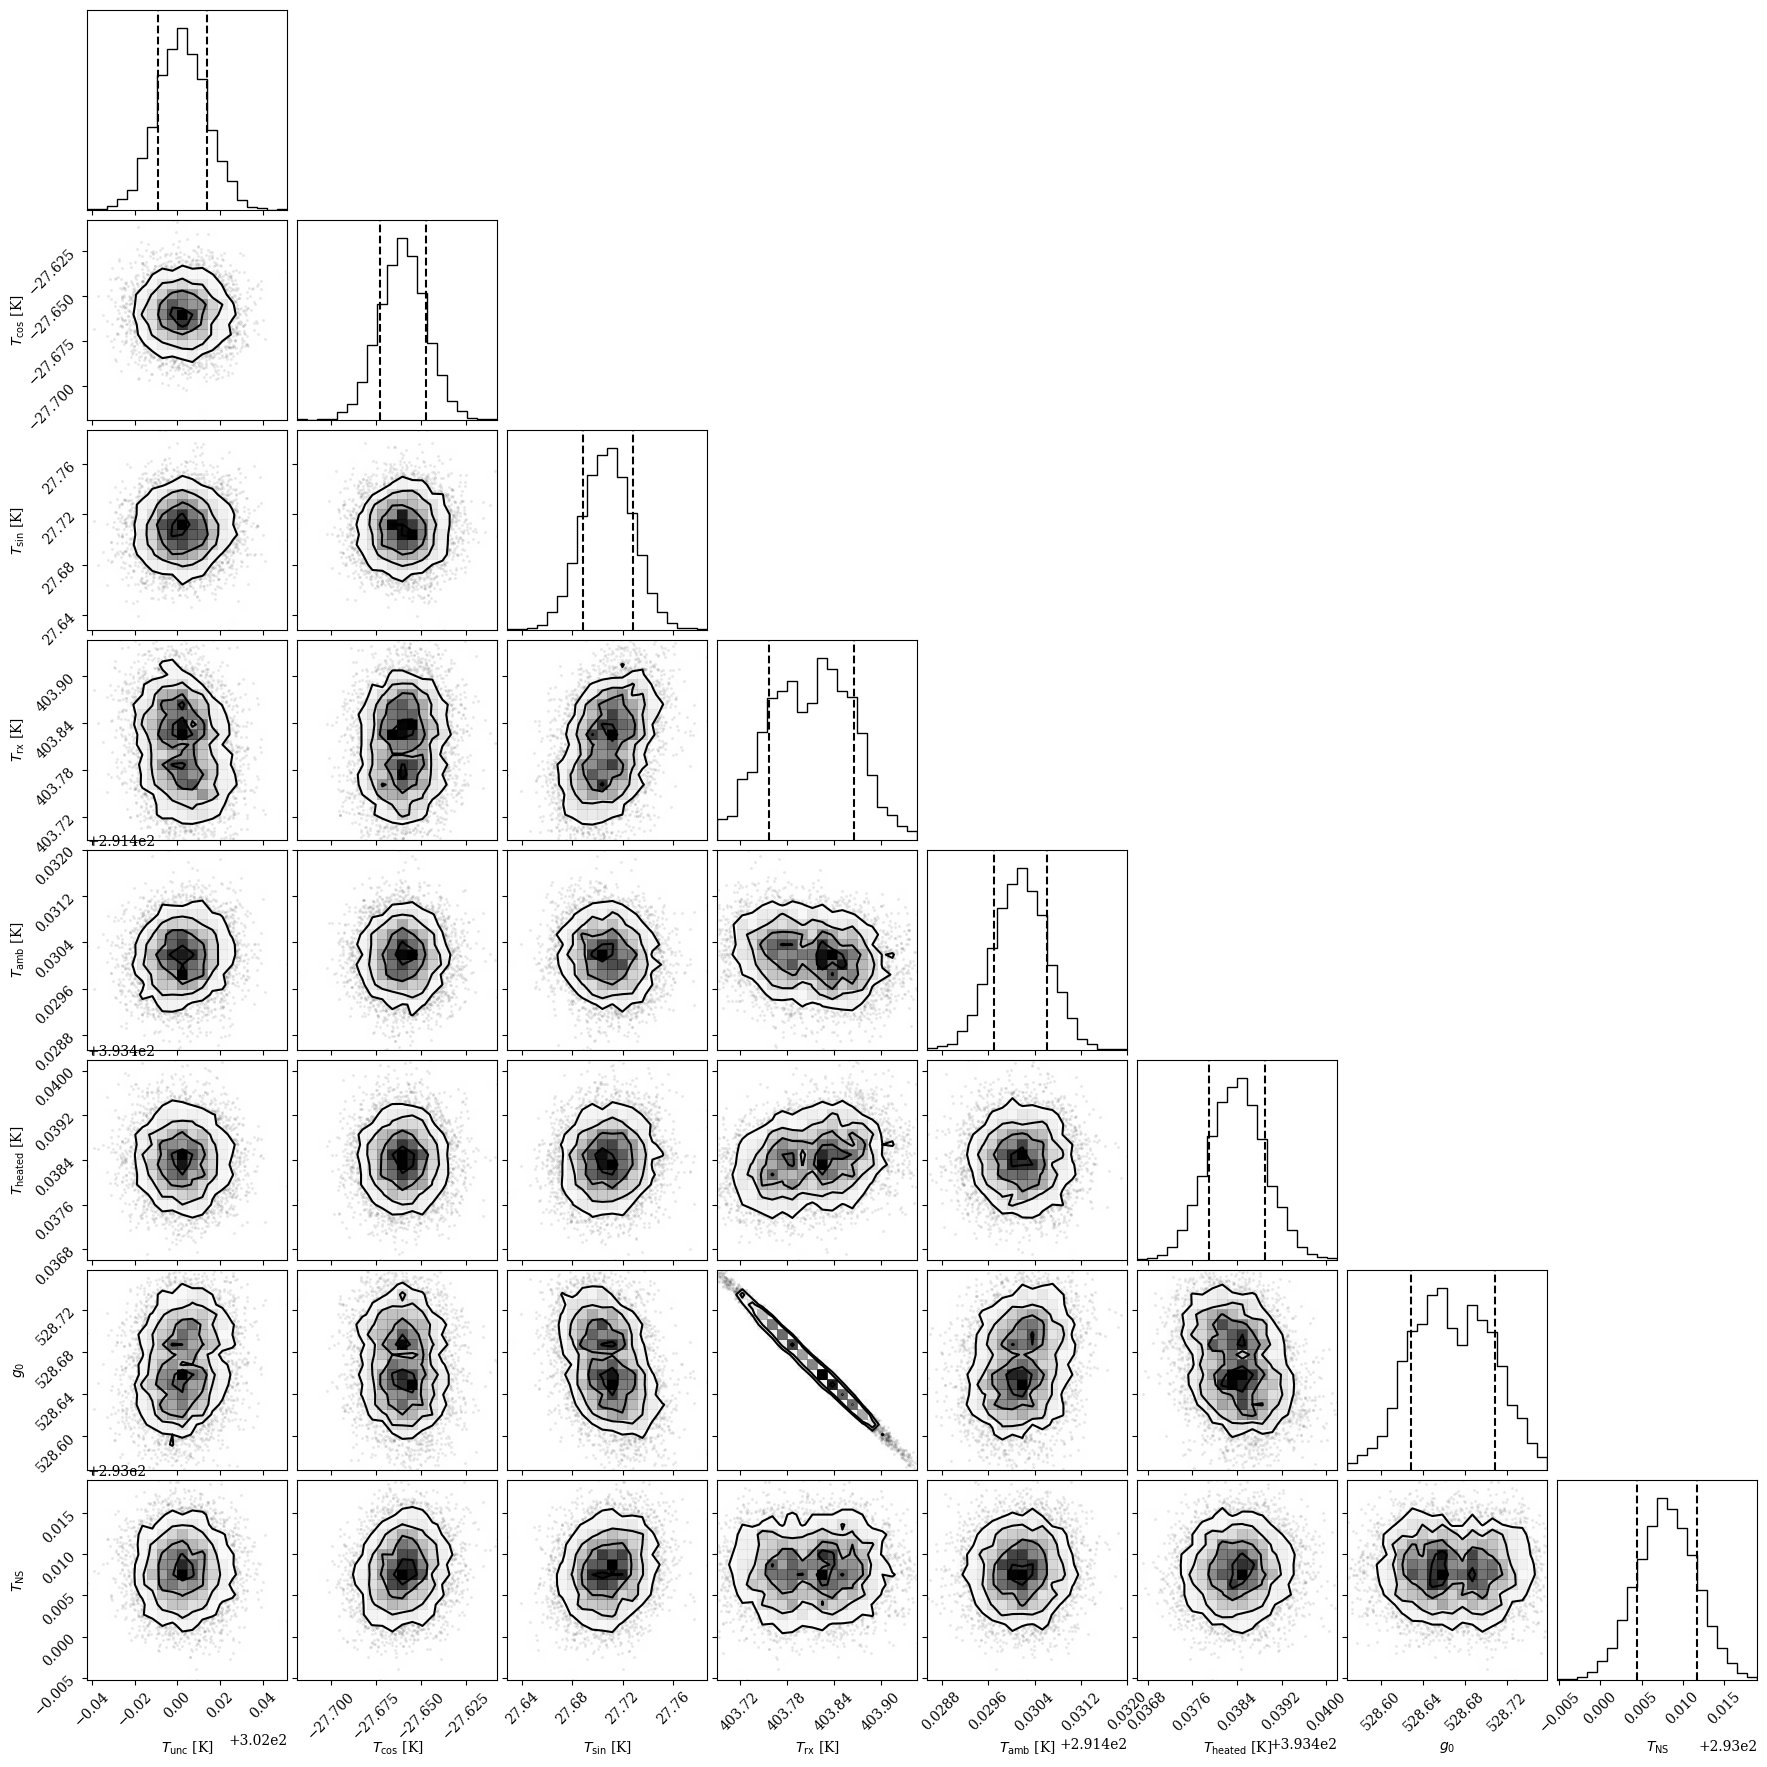

In [250]:

t_unc_chains = noise_wave_chains[:,nw_slice_dict['unc']]
t_sin_chains = noise_wave_chains[:,nw_slice_dict['sin']]
t_cos_chains = noise_wave_chains[:,nw_slice_dict['cos']]
t_rx_chains = noise_wave_chains[:,nw_slice_dict['rx']]

t_amb_chains = param_dict['all_p_cal_src'][:,calibrator_slice_dict_y['ambient']]
t_heated_chains = param_dict['all_p_cal_src'][:,calibrator_slice_dict_y['heated']]
print(t_amb_chains, t_heated_chains)

param_dict['all_p_gain']

gain_chain = param_dict['all_p_gain'][:,-1]



chains = np.column_stack([
    t_unc_chains[:,-1],
    t_cos_chains[:,-1],
    t_sin_chains[:,-1],
    t_rx_chains[:,-1],
    t_amb_chains[:,-1],
    t_heated_chains[:,-1],
    gain_chain,
    noise_diode_chain[:,-1]
])

fig = plot_corner(
    chains,
    labels=[
        r'$T_{\rm unc}$ [K]',
        r'$T_{\rm cos}$ [K]',
        r'$T_{\rm sin}$ [K]',
        r'$T_{\rm rx}$ [K]',
        r'$T_{\rm amb}$ [K]',
        r'$T_{\rm heated}$ [K]',
        r'$g_0$',
        r'$T_{\rm NS}$'
    ],
    truths=[
        np.mean(t_unc_sim),
        np.mean(t_cos_sim),
        np.mean(t_sin_sim),
        np.mean(t_rx_sim),
        293,
        293+150,
        np.mean(gain_sim),
        2600
    ]
)

plt.show()

# Construct $z$-score waterfall

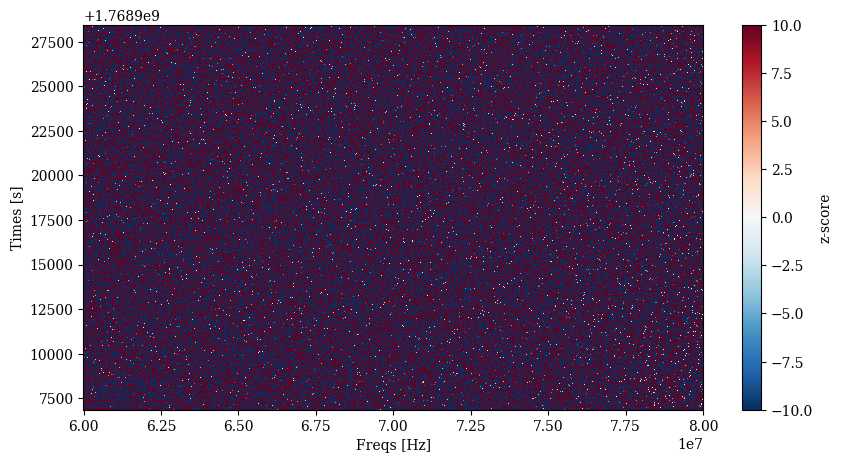

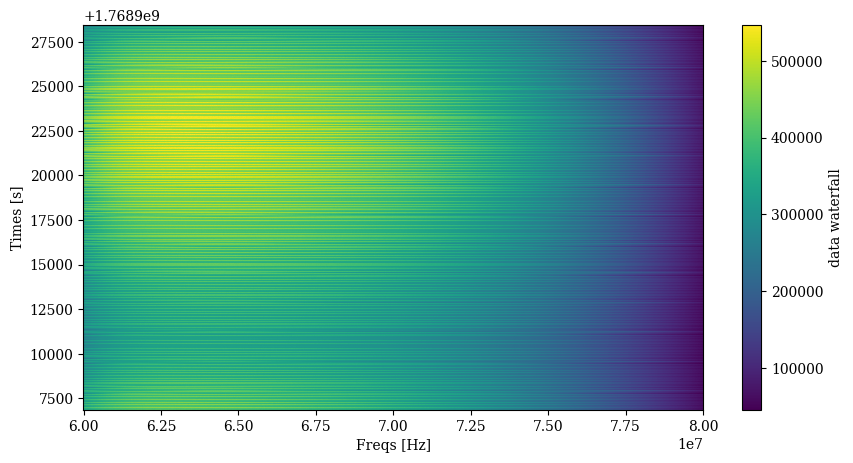

365.3118419319792


In [251]:
mad_model = (gains_basis.basis_matrix @ param_dict['all_p_gain'].mean(axis=0)) *\
    ((X_ant_noisewave @ param_dict['all_p_ant_nw'].mean(axis=0) + X_calibrator @ param_dict['all_p_cal_src'].mean(axis=0)))

cov = observation.Nw.flatten() * mad_model
sigma = np.sqrt(cov)
del cov

z = (observation.data_waterfall.flatten() - mad_model) / sigma
z = np.reshape(z, observation.data_waterfall.shape)

plt.pcolormesh(observation.freqs,
               observation.times,
               z,
               vmin=-10,
               vmax=10,
               cmap='RdBu_r')
plt.colorbar(label='z-score')
plt.ylabel('Times [s]')
plt.xlabel('Freqs [Hz]')
plt.show()


plt.pcolormesh(observation.freqs,
               observation.times,
               observation.data_waterfall,)
plt.colorbar(label='data waterfall')
plt.ylabel('Times [s]')
plt.xlabel('Freqs [Hz]')
plt.show()

print(np.median(np.abs(z)))

### Plot all Receiver calibration terms


In [252]:
def compare_sim_and_recontructed_all(true_gain_surface,
                                     gain_amplitudes,
                                     gain_basis:BasisConstructor,
                                     true_t_unc_surface,
                                     t_unc_amplitudes,
                                     t_unc_basis,
                                     true_t_cos_surface,
                                     t_cos_amplitudes,
                                     t_cos_basis:BasisConstructor,
                                     true_t_sin_surface,
                                     t_sin_amplitudes,
                                     t_sin_basis:BasisConstructor,
                                     true_t_rx_surface,
                                     t_rx_amplitudes,
                                     t_rx_basis:BasisConstructor,
                                     waterfall_shape,
                                     times,
                                     freqs,
                                     cmap_rec='viridis',
                                     cmap_res='RdBu',
                                     perc_diff=False,
                                     residvminvmax=None,
                                     figsize=(10,8),
                                     gain_cmap='viridis',
                                     t_unc_cmap='plasma',
                                     t_cos_cmap='inferno',
                                     t_sin_cmap='cividis',
                                     t_rx_cmap='magma',
                                     savepath: str|None=None):

    fig, axes = plt.subplots(
        nrows=3,
        ncols=5,
        sharex=True,
        layout='constrained',
        figsize=figsize,
        sharey=True
        )

    freqs /= 1e6
    
    # Gains
    rec_gain_surface = gains_basis.basis_matrix @ gain_amplitudes
    rec_gain_surface = np.reshape(
        rec_gain_surface,
        waterfall_shape
    )

    gain = axes[0,0].pcolormesh(
        freqs,
        times,
        true_gain_surface,
        cmap=gain_cmap
    )
    gain = axes[1,0].pcolormesh(
            freqs,
            times,
            rec_gain_surface,
            cmap=gain_cmap
        )

    perc_diff = 200*(true_gain_surface - rec_gain_surface) / \
        (true_gain_surface + rec_gain_surface)

    res = axes[2,0].pcolormesh(
            freqs,
            times,
            perc_diff,
            cmap=cmap_res,
            vmin=-residvminvmax,
            vmax=residvminvmax
        )

    del rec_gain_surface, true_gain_surface,perc_diff


    # Unc
    rec_unc_surface = unc_basis.basis_matrix @ t_unc_amplitudes
    rec_unc_surface = np.reshape(
        rec_unc_surface,
        waterfall_shape
    )

    unc = axes[0,1].pcolormesh(
        freqs,
        times,
        true_t_unc_surface,
        cmap=t_unc_cmap
    )
    unc = axes[1,1].pcolormesh(
            freqs,
            times,
            rec_unc_surface,
            cmap=t_unc_cmap
        )

    perc_diff = 200*(true_t_unc_surface - rec_unc_surface) / \
        (true_t_unc_surface + rec_unc_surface)

    res = axes[2,1].pcolormesh(
            freqs,
            times,
            perc_diff,
            cmap=cmap_res,
            vmin=-residvminvmax,
            vmax=residvminvmax
        )

    del rec_unc_surface, true_t_unc_surface,perc_diff


    # Cos
    rec_cos_surface = cos_basis.basis_matrix @ t_cos_amplitudes
    rec_cos_surface = np.reshape(
        rec_cos_surface,
        waterfall_shape
    )

    cos = axes[0,2].pcolormesh(
        freqs,
        times,
        true_t_cos_surface,
        cmap=t_cos_cmap
    )
    cos = axes[1,2].pcolormesh(
            freqs,
            times,
            rec_cos_surface,
            cmap=t_cos_cmap
        )

    perc_diff = 200*(true_t_cos_surface - rec_cos_surface) / \
        (true_t_cos_surface + rec_cos_surface)

    res = axes[2,2].pcolormesh(
            freqs,
            times,
            perc_diff,
            cmap=cmap_res,
            vmin=-residvminvmax,
            vmax=residvminvmax
        )

    del rec_cos_surface, true_t_cos_surface,perc_diff

    # Sin
    rec_sin_surface = sin_basis.basis_matrix @ t_sin_amplitudes
    rec_sin_surface = np.reshape(
        rec_sin_surface,
        waterfall_shape
    )

    sin = axes[0,3].pcolormesh(
        freqs,
        times,
        true_t_sin_surface,
        cmap=t_sin_cmap
    )
    sin = axes[1,3].pcolormesh(
            freqs,
            times,
            rec_sin_surface,
            cmap=t_sin_cmap
        )

    perc_diff = 200*(true_t_sin_surface - rec_sin_surface) / \
        (true_t_sin_surface + rec_sin_surface)

    res = axes[2,3].pcolormesh(
            freqs,
            times,
            perc_diff,
            cmap=cmap_res,
            vmin=-residvminvmax,
            vmax=residvminvmax
        )

    del rec_sin_surface, true_t_sin_surface,perc_diff

    # Rx
    rec_rx_surface = rx_basis.basis_matrix @ t_rx_amplitudes
    rec_rx_surface = np.reshape(
        rec_rx_surface,
        waterfall_shape
    )

    rx = axes[0,4].pcolormesh(
        freqs,
        times,
        true_t_rx_surface,
        cmap=t_rx_cmap
    )
    rx = axes[1,4].pcolormesh(
            freqs,
            times,
            rec_rx_surface,
            cmap=t_rx_cmap
        )

    perc_diff = 200*(true_t_rx_surface - rec_rx_surface) / \
        (true_t_rx_surface + rec_rx_surface)

    res = axes[2,4].pcolormesh(
            freqs,
            times,
            perc_diff,
            cmap=cmap_res,
            vmin=-residvminvmax,
            vmax=residvminvmax
        )

    del rec_rx_surface, true_t_rx_surface,perc_diff

    axes[0,0].set_ylabel('True')
    axes[1,0].set_ylabel('Maximum Likelihood')

    fig.colorbar(res,
                 ax=[axes[2,i] for i in range(5)],
                 label='% Difference',
                 extend='both')

    fig.colorbar(
        unc,
        ax=[axes[i,1] for i in range(2)],
        label=r'$T_{\rm unc}$ [K]'
    )
    fig.colorbar(
            cos,
            ax=[axes[i,2] for i in range(2)],
            label=r'$T_{\rm cos}$ [K]'
        )
    fig.colorbar(
            sin,
            ax=[axes[i,3] for i in range(2)],
            label=r'$T_{\rm sin}$ [K]'
        )
    fig.colorbar(
            rx,
            ax=[axes[i,4] for i in range(2)],
            label=r'$T_{\rm rx}$ [K]'
        )
    fig.colorbar(
            gain,
            ax=[axes[i,0] for i in range(2)],
            label=r'Gain [K$^{-1}$]'
        )

    fig.supxlabel(r'Freq [MHz]')
    fig.supylabel(r'Time [s]')
    if savepath is not None:
        fig.savefig(fname=savepath)
    plt.show()
    

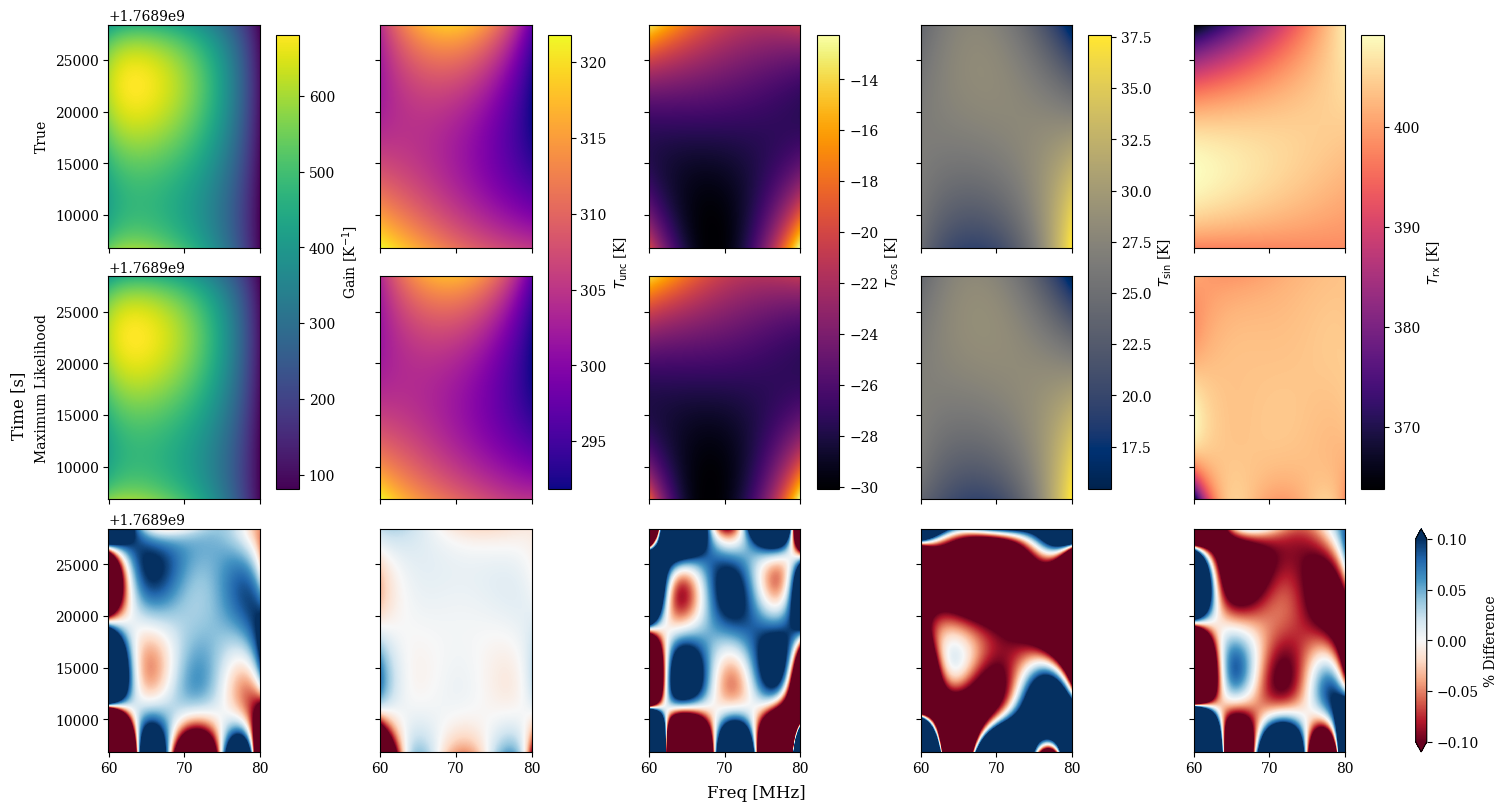

In [253]:
compare_sim_and_recontructed_all(
    true_gain_surface=gain_sim,
    gain_amplitudes=mean_gains,
    gain_basis=gains_basis,
    true_t_unc_surface=t_unc_sim,
    t_unc_amplitudes=mean_unc,
    t_unc_basis=unc_basis,
    true_t_cos_surface=t_cos_sim,
    t_cos_amplitudes=mean_cos,
    t_cos_basis=cos_basis,
    true_t_sin_surface=t_sin_sim,
    t_sin_amplitudes=mean_sin,
    t_sin_basis=sin_basis,
    true_t_rx_surface=t_rx_sim,
    t_rx_amplitudes=mean_rx,
    t_rx_basis=rx_basis,
    waterfall_shape=observation.data_waterfall.shape,
    times=observation.times,
    freqs=observation.freqs,
    residvminvmax=0.1,
    figsize=(15,8),
    # savepath='plots/calibration_map_sol.pdf'
)

In [254]:
def return_rmsd(true_surface,
                chains,
                basis_obj:BasisConstructor,):
    square_error_sum = np.zeros_like(true_surface)

    for chain in chains:
        res_surface = basis_obj.basis_matrix @ chain
        res_surface = np.reshape(res_surface, shape=true_surface.shape)
        square_error_sum += np.power((true_surface - res_surface), 2)
    rmsd = np.sqrt(square_error_sum / len(chains))
    return rmsd

def compare_sim_and_recontructed_all_from_chain(true_gain_surface,
                                                gain_chain,
                                                gain_basis:BasisConstructor,
                                                true_t_unc_surface,
                                     t_unc_chain,
                                     t_unc_basis,
                                     true_t_cos_surface,
                                     t_cos_chain,
                                     t_cos_basis:BasisConstructor,
                                     true_t_sin_surface,
                                     t_sin_chain,
                                     t_sin_basis:BasisConstructor,
                                     true_t_rx_surface,
                                     t_rx_chain,
                                     t_rx_basis:BasisConstructor,
                                     waterfall_shape,
                                     times,
                                     freqs,
                                     cmap_rec='viridis',
                                     cmap_res='RdBu',
                                     cmap_rmsd='berlin',
                                     perc_diff=False,
                                     residvminvmax=None,
                                     figsize=(10,8),
                                     gain_cmap='viridis',
                                     t_unc_cmap='plasma',
                                     t_cos_cmap='inferno',
                                     t_sin_cmap='cividis',
                                     t_rx_cmap='magma',
                                     rmsd_vmin=0,
                                     rmsd_vmax=5,
                                     savepath: str|None=None):

    fig, axes = plt.subplots(
        nrows=4,
        ncols=5,
        sharex=True,
        layout='constrained',
        figsize=figsize,
        sharey=True
        )

    freqs = np.linspace(60, 80, waterfall_shape[1])
    gain_amplitudes = np.mean(gain_chain, axis=0)
    # Gains
    rec_gain_surface = gains_basis.basis_matrix @ gain_amplitudes
    rec_gain_surface = np.reshape(
        rec_gain_surface,
        waterfall_shape
    )

    gain = axes[0,0].pcolormesh(
        freqs,
        times,
        true_gain_surface,
        cmap=gain_cmap
    )
    gain = axes[1,0].pcolormesh(
            freqs,
            times,
            rec_gain_surface,
            cmap=gain_cmap
        )

    perc_diff = 200*(true_gain_surface - rec_gain_surface) / \
        (true_gain_surface + rec_gain_surface)

    res = axes[2,0].pcolormesh(
            freqs,
            times,
            perc_diff,
            cmap=cmap_res,
            vmin=-residvminvmax,
            vmax=residvminvmax
        )

    gain_rmsd = return_rmsd(rec_gain_surface, gain_chain, gains_basis)
    rmsd = axes[3,0].pcolormesh(
            freqs,
            times,
            100*gain_rmsd / rec_gain_surface,
            cmap=cmap_rmsd,
            vmin=rmsd_vmin,
            vmax=rmsd_vmax
        )

    del rec_gain_surface, true_gain_surface,perc_diff, gain_rmsd

    t_unc_amplitudes = np.mean(t_unc_chain, axis=0)
    # Unc
    rec_unc_surface = unc_basis.basis_matrix @ t_unc_amplitudes
    rec_unc_surface = np.reshape(
        rec_unc_surface,
        waterfall_shape
    )

    unc = axes[0,1].pcolormesh(
        freqs,
        times,
        true_t_unc_surface,
        cmap=t_unc_cmap
    )
    unc = axes[1,1].pcolormesh(
            freqs,
            times,
            rec_unc_surface,
            cmap=t_unc_cmap
        )

    perc_diff = 200*(true_t_unc_surface - rec_unc_surface) / \
        (true_t_unc_surface + rec_unc_surface)

    res = axes[2,1].pcolormesh(
            freqs,
            times,
            perc_diff,
            cmap=cmap_res,
            vmin=-residvminvmax,
            vmax=residvminvmax
        )

    unc_rmsd = return_rmsd(rec_unc_surface, t_unc_chain, unc_basis)
    rmsd = axes[3,1].pcolormesh(
            freqs,
            times,
            100*unc_rmsd / rec_unc_surface,
            cmap=cmap_rmsd,
            vmin=rmsd_vmin,
            vmax=rmsd_vmax
        )

    del rec_unc_surface, true_t_unc_surface,perc_diff, unc_rmsd

    t_cos_amplitudes = np.mean(t_cos_chain, axis=0)
    # Cos
    rec_cos_surface = cos_basis.basis_matrix @ t_cos_amplitudes
    rec_cos_surface = np.reshape(
        rec_cos_surface,
        waterfall_shape
    )

    cos = axes[0,2].pcolormesh(
        freqs,
        times,
        true_t_cos_surface,
        cmap=t_cos_cmap
    )
    cos = axes[1,2].pcolormesh(
            freqs,
            times,
            rec_cos_surface,
            cmap=t_cos_cmap
        )

    perc_diff = 200*(true_t_cos_surface - rec_cos_surface) / \
        (true_t_cos_surface + rec_cos_surface)

    res = axes[2,2].pcolormesh(
            freqs,
            times,
            perc_diff,
            cmap=cmap_res,
            vmin=-residvminvmax,
            vmax=residvminvmax
        )

    cos_rmsd = return_rmsd(rec_cos_surface, t_cos_chain, cos_basis)
    rmsd = axes[3,2].pcolormesh(
            freqs,
            times,
            100*cos_rmsd / rec_cos_surface,
            cmap=cmap_rmsd,
            vmin=rmsd_vmin,
            vmax=rmsd_vmax
        )

    del rec_cos_surface, true_t_cos_surface,perc_diff, cos_rmsd

    # Sin
    t_sin_amplitudes = np.mean(t_sin_chain, axis=0)
    rec_sin_surface = sin_basis.basis_matrix @ t_sin_amplitudes
    rec_sin_surface = np.reshape(
        rec_sin_surface,
        waterfall_shape
    )

    sin = axes[0,3].pcolormesh(
        freqs,
        times,
        true_t_sin_surface,
        cmap=t_sin_cmap
    )
    sin = axes[1,3].pcolormesh(
            freqs,
            times,
            rec_sin_surface,
            cmap=t_sin_cmap
        )

    perc_diff = 200*(true_t_sin_surface - rec_sin_surface) / \
        (true_t_sin_surface + rec_sin_surface)

    res = axes[2,3].pcolormesh(
            freqs,
            times,
            perc_diff,
            cmap=cmap_res,
            vmin=-residvminvmax,
            vmax=residvminvmax
        )

    sin_rmsd = return_rmsd(rec_sin_surface, t_sin_chain, sin_basis)
    rmsd = axes[3,3].pcolormesh(
            freqs,
            times,
            100*sin_rmsd / rec_sin_surface,
            cmap=cmap_rmsd,
            vmin=rmsd_vmin,
            vmax=rmsd_vmax
        )
    del rec_sin_surface, true_t_sin_surface,perc_diff, sin_rmsd

    # Rx
    t_rx_amplitudes = np.mean(t_rx_chain, axis=0)
    rec_rx_surface = rx_basis.basis_matrix @ t_rx_amplitudes
    rec_rx_surface = np.reshape(
        rec_rx_surface,
        waterfall_shape
    )

    rx = axes[0,4].pcolormesh(
        freqs,
        times,
        true_t_rx_surface,
        cmap=t_rx_cmap
    )
    rx = axes[1,4].pcolormesh(
            freqs,
            times,
            rec_rx_surface,
            cmap=t_rx_cmap
        )

    perc_diff = 200*(true_t_rx_surface - rec_rx_surface) / \
        (true_t_rx_surface + rec_rx_surface)

    res = axes[2,4].pcolormesh(
            freqs,
            times,
            perc_diff,
            cmap=cmap_res,
            vmin=-residvminvmax,
            vmax=residvminvmax
        )

    rx_rmsd = return_rmsd(rec_rx_surface, t_rx_chain, rx_basis)
    rmsd = axes[3,4].pcolormesh(
            freqs,
            times,
            100*rx_rmsd / rec_rx_surface,
            cmap=cmap_rmsd,
            vmin=rmsd_vmin,
            vmax=rmsd_vmax
        )
    del rec_rx_surface, true_t_rx_surface,perc_diff, rx_rmsd

    axes[0,0].set_ylabel('True')
    axes[1,0].set_ylabel('Maximum Likelihood')

    fig.colorbar(res,
                 ax=[axes[2,i] for i in range(5)],
                 label='Difference [%]',
                 extend='both')
    
    fig.colorbar(
            rmsd,
            ax=[axes[3,i] for i in range(5)],
            label='Sample RMSD / Sample Mean [%]',
            extend='both'
        )

    fig.colorbar(
        unc,
        ax=[axes[i,1] for i in range(2)],
        label=r'$T_{\rm unc}$ [K]'
    )
    fig.colorbar(
            cos,
            ax=[axes[i,2] for i in range(2)],
            label=r'$T_{\rm cos}$ [K]'
        )
    fig.colorbar(
            sin,
            ax=[axes[i,3] for i in range(2)],
            label=r'$T_{\rm sin}$ [K]'
        )
    fig.colorbar(
            rx,
            ax=[axes[i,4] for i in range(2)],
            label=r'$T_{\rm rx}$ [K]'
        )
    fig.colorbar(
            gain,
            ax=[axes[i,0] for i in range(2)],
            label=r'Gain [K$^{-1}$]'
        )


    fig.supxlabel(r'Freq [MHz]')
    fig.supylabel(r'Time [s]')
    if savepath is not None:
        fig.savefig(fname=savepath)
    plt.show()
    

In [255]:
# compare_sim_and_recontructed_all_from_chain(
#     true_gain_surface=gain_sim,
#     gain_chain=param_dict['all_p_gain'],
#     gain_basis=gains_basis,
#     true_t_unc_surface=t_unc_sim,
#     t_unc_chain=t_unc_chains,
#     t_unc_basis=unc_basis,
#     true_t_cos_surface=t_cos_sim,
#     t_cos_chain=t_cos_chains,
#     t_cos_basis=cos_basis,
#     true_t_sin_surface=t_sin_sim,
#     t_sin_chain=t_sin_chains,
#     t_sin_basis=sin_basis,
#     true_t_rx_surface=t_rx_sim,
#     t_rx_chain=t_rx_chains,
#     t_rx_basis=rx_basis,
#     waterfall_shape=observation.data_waterfall.shape,
#     times=observation.times,
#     freqs=observation.freqs,
#     residvminvmax=0.1,
#     figsize=(15,8),
#     rmsd_vmin=-0.1,
#     rmsd_vmax=0.1,
#     # savepath='plots/calibration_map_sol.pdf'
# )

# Plot 1D Distribution


In [256]:
def plot_1d_spectra(
        true_surface,
        basis:BasisConstructor,
        chains,
        freqs,
        waterfall_shape,
        ylabel,
        color='green',
):
    quantiles = [0.5-(0.97/2),
                 0.5-(0.68/2),
                 0.5,
                 0.5+(0.97/2),
                 0.5+(0.68/2)]
    # Get the quantiled from chains
    param_quantile_list = [
        np.quantile(chains,
                    q,
                    axis=0) for q in quantiles
    ]
    mean_chain = np.mean(chains, axis=0)

    true_spectra = np.mean(true_surface, axis=0)
    del true_surface
    def reproduce_spectra(amps):
        rec = basis.basis_matrix @ amps
        rec = np.reshape(rec, waterfall_shape)
        return rec.mean(axis=0)


    mean_chain_spectra = reproduce_spectra(mean_chain)
    median_chain_spectra = reproduce_spectra(np.quantile(chains,
                                                         0.5,
                                                         axis=0))

    one_sigma_bounds = [reproduce_spectra(np.quantile(chains,
                                                         0.5-(0.68/2),
                                                         axis=0)),
                        reproduce_spectra(np.quantile(chains,
                                                      0.5+(0.68/2),
                                                      axis=0)),]


    reproduced_gains = np.array(
        [reproduce_spectra(chain_i) for chain_i in chains]
        )

    mean_gain = np.mean(reproduced_gains, axis=0)
    median_gain = np.median(reproduced_gains, axis=0)

    sigma_bounds = [
        np.quantile(reproduced_gains, 0.5-(0.68/2), axis=0),
        np.quantile(reproduced_gains, 0.5+(0.68/2), axis=0)
    ]
    three_sigma_bounds = [
            np.quantile(reproduced_gains, 0.5-(0.997/2), axis=0),
            np.quantile(reproduced_gains, 0.5+(0.997/2), axis=0)
        ]

    plt.plot(freqs, true_spectra, label='Truth')
    plt.plot(freqs, mean_gain, label='Mean')
    plt.plot(freqs, median_gain, label='Median')
    plt.fill_between(freqs, sigma_bounds[0], sigma_bounds[-1],
                     color=color, alpha=0.25)
    
    plt.fill_between(freqs, three_sigma_bounds[0], three_sigma_bounds[-1],
                     color=color, alpha=0.25)
    
    plt.show()
    plt.plot(freqs, mean_gain-true_spectra, label='Mean')
    plt.plot(freqs, median_gain-true_spectra, label='Median')
    plt.fill_between(freqs, sigma_bounds[0]-true_spectra, 
                     sigma_bounds[-1]-true_spectra,
                         color=color, alpha=0.25)
    plt.fill_between(freqs, three_sigma_bounds[0]-true_spectra, 
                         three_sigma_bounds[-1]-true_spectra,
                             color=color, alpha=0.25)
    plt.legend()
    plt.show()


    

In [257]:
# plot_1d_spectra(gain_sim,
#                 basis=gains_basis,
#                 chains=param_dict['all_p_gain'],
#                 freqs=observation.freqs,
#                 waterfall_shape=observation.data_waterfall.shape,
#                 ylabel='')
# plot_1d_spectra(t_rx_sim,
#                 basis=rx_basis,
#                 chains=t_rx_chains,
#                 freqs=observation.freqs,
#                 waterfall_shape=observation.data_waterfall.shape,
#                 ylabel=r'$T_{\rm rx}$',
#                 color='red')
# plot_1d_spectra(t_cos_sim,
#                 basis=cos_basis,
#                 chains=t_cos_chains,
#                 freqs=observation.freqs,
#                 waterfall_shape=observation.data_waterfall.shape,
#                 ylabel=r'$T_{\rm cos}$',
#                 color='blue')
# plot_1d_spectra(t_sin_sim,
#                 basis=sin_basis,
#                 chains=t_sin_chains,
#                 freqs=observation.freqs,
#                 waterfall_shape=observation.data_waterfall.shape,
#                 ylabel=r'$T_{\rm sin}$',
#                 color='orange')
# plot_1d_spectra(t_unc_sim,
#                 basis=unc_basis,
#                 chains=t_unc_chains,
#                 freqs=observation.freqs,
#                 waterfall_shape=observation.data_waterfall.shape,
#                 ylabel=r'$T_{\rm sin}$',
#                 color='purple')

In [258]:
def plot_all_1d_cal_spectra(
        gain_chain,
        unc_chain,
        cos_chain,
        sin_chain,
        rx_chain,
        gain_basis,
        unc_basis,
        cos_basis,
        sin_basis,
        rx_basis,
        true_gains,
        true_unc,
        true_cos,
        true_sin,
        true_rx,
        waterfall_shape,
        freqs,
        c_gain='green',
        c_unc='purple',
        c_cos='red',
        c_sin='blue',
        c_rx='orangered',
        c_true='black',
        saveplot=None,
        figsize=(15,10),
        alpha=0.25,
):
    fig, axes = plt.subplots(
        nrows=2,
        ncols=5,
        layout='constrained',
        figsize=figsize,
        sharex=True,
    )

    def plot_comp(full_ax,
                  resid_ax,
                  chain,
                  basis,
                  true_spec,
                  color,
                  alpha):
        def reproduce_spectra(amps):
                rec = basis.basis_matrix @ amps
                rec = np.reshape(rec, waterfall_shape)
                return rec.mean(axis=0)
        reproduced_spectra = np.array(
                [reproduce_spectra(chain_i) for chain_i in chain]
                )
        true_spec = true_spec.mean(axis=0) # convert surface to 1D

        med_spectra = np.quantile(reproduced_spectra,
                                  0.5, axis=0)
        sigma_bounds = [
                np.quantile(reproduced_spectra, 0.5-(0.68/2), axis=0),
                np.quantile(reproduced_spectra, 0.5+(0.68/2), axis=0)
            ]
        three_sigma_bounds = [
                    np.quantile(reproduced_spectra, 0.5-(0.997/2), axis=0),
                    np.quantile(reproduced_spectra, 0.5+(0.997/2), axis=0)
                ]
        

        full_ax.plot(freqs, true_spec, c=c_true, label='True')
        full_ax.plot(freqs, med_spectra, c=color, label='Max Prob.')
        full_ax.fill_between(freqs, sigma_bounds[0], sigma_bounds[-1],
                             color=color, alpha=2*alpha, label=r'$1\,\sigma$')
        full_ax.fill_between(freqs, three_sigma_bounds[0], three_sigma_bounds[-1],
                                     color=color, alpha=alpha, label=r'$3\,\sigma$')

        resid_ax.plot(freqs, med_spectra - true_spec, c=color)
        resid_ax.fill_between(freqs, sigma_bounds[0]-true_spec,
                              sigma_bounds[-1]-true_spec,
                                     color=color, alpha=2*alpha)
        resid_ax.fill_between(freqs, three_sigma_bounds[0]-true_spec,
                              three_sigma_bounds[-1]-true_spec,
                                             color=color, alpha=alpha)
        resid_ax.plot(freqs, np.zeros_like(freqs), ls='--', c='black')
        pass


    plot_comp(axes[0,0], axes[1,0], chain=gain_chain, basis=gain_basis,
              true_spec=true_gains, color=c_gain, alpha=alpha)
    plot_comp(axes[0,1], axes[1,1], chain=unc_chain, basis=unc_basis,
                  true_spec=true_unc, color=c_unc, alpha=alpha)
    plot_comp(axes[0,2], axes[1,2], chain=cos_chain, basis=cos_basis,
                  true_spec=true_cos, color=c_cos, alpha=alpha)
    plot_comp(axes[0,3], axes[1,3], chain=sin_chain, basis=sin_basis,
                  true_spec=true_sin, color=c_sin, alpha=alpha)
    plot_comp(axes[0,4], axes[1,4], chain=rx_chain, basis=rx_basis,
                  true_spec=true_rx, color=c_rx, alpha=alpha)

    fig.supxlabel(r'Frequency [MHz]')

    axes[0,0].set_ylabel(r'Gain [K$^{-1}$]')
    axes[0,1].set_ylabel(r'$T_{\rm unc}$ [K]')
    axes[0,2].set_ylabel(r'$T_{\rm cos}$ [K]')
    axes[0,3].set_ylabel(r'$T_{\rm sin}$ [K]')
    axes[0,4].set_ylabel(r'$T_{\rm rx}$ [K]')
    axes[1,0].set_ylabel(r'Residual [K$^{-1}$]')
    axes[1,1].set_ylabel(r'Residual [K]')
    axes[0,0].legend(frameon=False)
    if saveplot is not None:
        fig.savefig(saveplot)
    plt.show()



        

In [259]:
# plot_all_1d_cal_spectra(gain_chain=param_dict['all_p_gain'],
#                         unc_chain=t_unc_chains,
#                         cos_chain=t_cos_chains,
#                         sin_chain=t_sin_chains,
#                         rx_chain=t_rx_chains,
#                         gain_basis=gains_basis,
#                         unc_basis=unc_basis,
#                         cos_basis=cos_basis,
#                         sin_basis=sin_basis,
#                         rx_basis=rx_basis,
#                         true_gains=gain_sim,
#                         true_unc=t_unc_sim,
#                         true_cos=t_cos_sim,
#                         true_sin=t_sin_sim,
#                         true_rx=t_rx_sim,
#                         waterfall_shape=observation.data_waterfall.shape,
#                         freqs=observation.freqs,
#                         figsize=(16,8),
#                         # saveplot='../plots/case1_1d_recovery.pdf'
#                         )

### Plotting for the spectral, time static case.

Create plots of the various 

# Source Recovery

In [260]:
def source_recovery(data_waterfall,
                    times,
                    freqs,
                    states_array,
                    reflection_obj:ReflectionReader,
                    gain_coeffs,
                    U_gain,
                    nw_coeffs,
                    X_nw,
                    source='antenna'):
    gains = U_gain @ gain_coeffs
    nw_contributions = X_nw @ nw_coeffs

    gains = np.reshape(gains, data_waterfall.shape)
    nw_contributions = np.reshape(nw_contributions, data_waterfall.shape) # includes the reflections

    scaled_data = (data_waterfall / gains) - nw_contributions # K weighted by src temp

    # select data
    source_mask = (states_array == source)
    source_data = scaled_data[source_mask]
    source_times = times[source_mask]

    cs_src = reflection_obj.cs_dict[source]

    t_src = source_data / cs_src

    return t_src, source_times, freqs

    

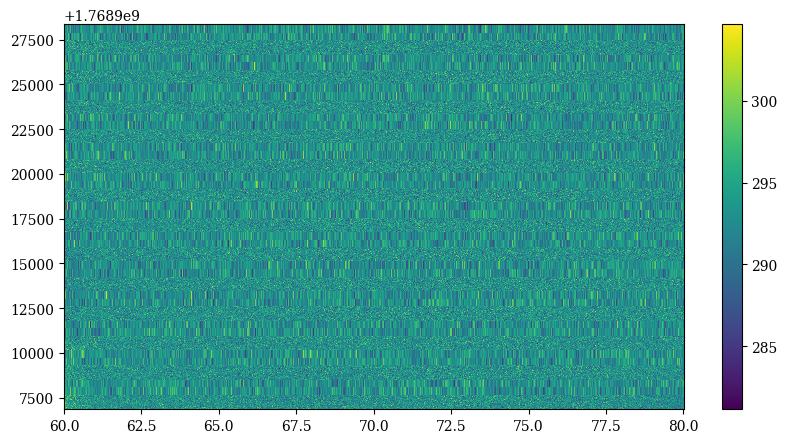

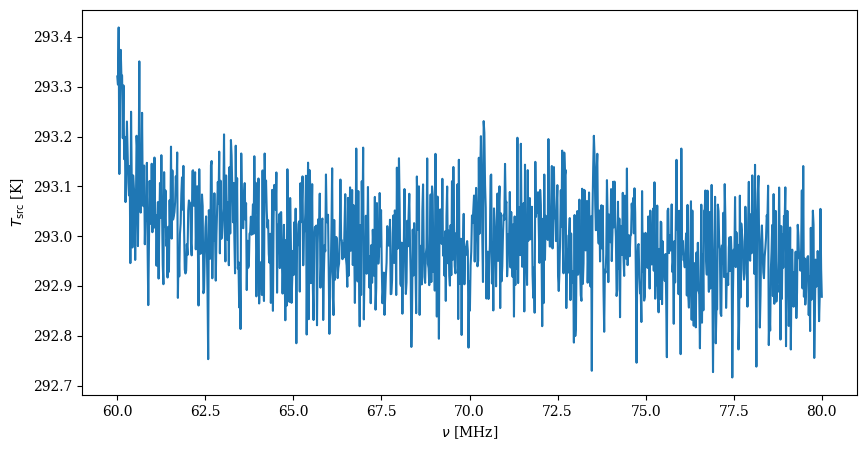

292.9929949766497
0.09804297789940522


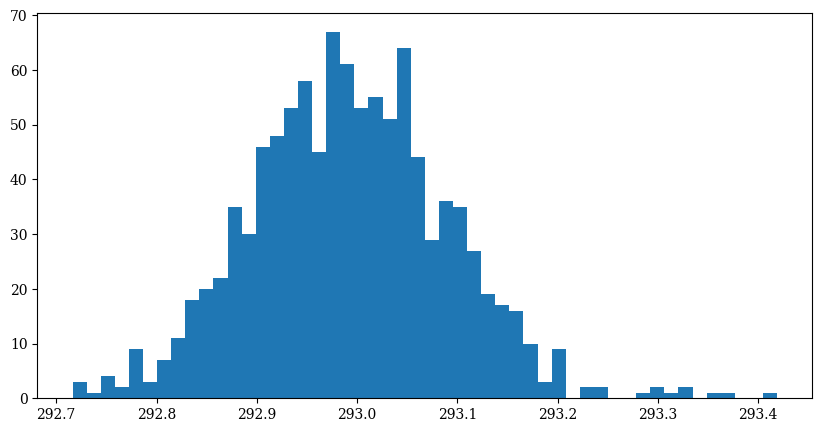

In [261]:
# Recover only source temperatures

gain_coeffs = np.median(param_dict['all_p_gain'],axis=0)
nw_coeffs = np.median(param_dict['all_p_ant_nw'], axis=0)[ant_noise_wave_slice_dict['noise_wave']]

source_temperatures, source_times, source_freqs = source_recovery(observation.data_waterfall,
                                                                  observation.times,
                                                                  observation.freqs,
                                                                  states_array=observation.states_array,
                                                                  reflection_obj=reflections,
                                                                  gain_coeffs=gain_coeffs,
                                                                  U_gain=U_gain,
                                                                  nw_coeffs=nw_coeffs,
                                                                  X_nw = X_noise_wave,
                                                                  source='antenna')


plt.pcolormesh(source_freqs,
               source_times,
               source_temperatures)
plt.colorbar()
plt.show()

plt.plot(source_freqs, source_temperatures.mean(axis=0))
plt.ylabel(r'$T_{\rm src}$ [K]')
plt.xlabel(r'$\nu$ [MHz]')
plt.show()

print(np.mean(source_temperatures.mean(axis=0)))
print(np.std(source_temperatures.mean(axis=0)))

plt.hist(source_temperatures.mean(axis=0), bins=50)
plt.show()

# Correlation Coefficient Plot

61 62
slice(0, 49, None) slice(49, 61, None) slice(61, 162, None)
(162,)
(162, 162)
(array([  0,  49,  55,  61,  62,  87, 112, 137]),)


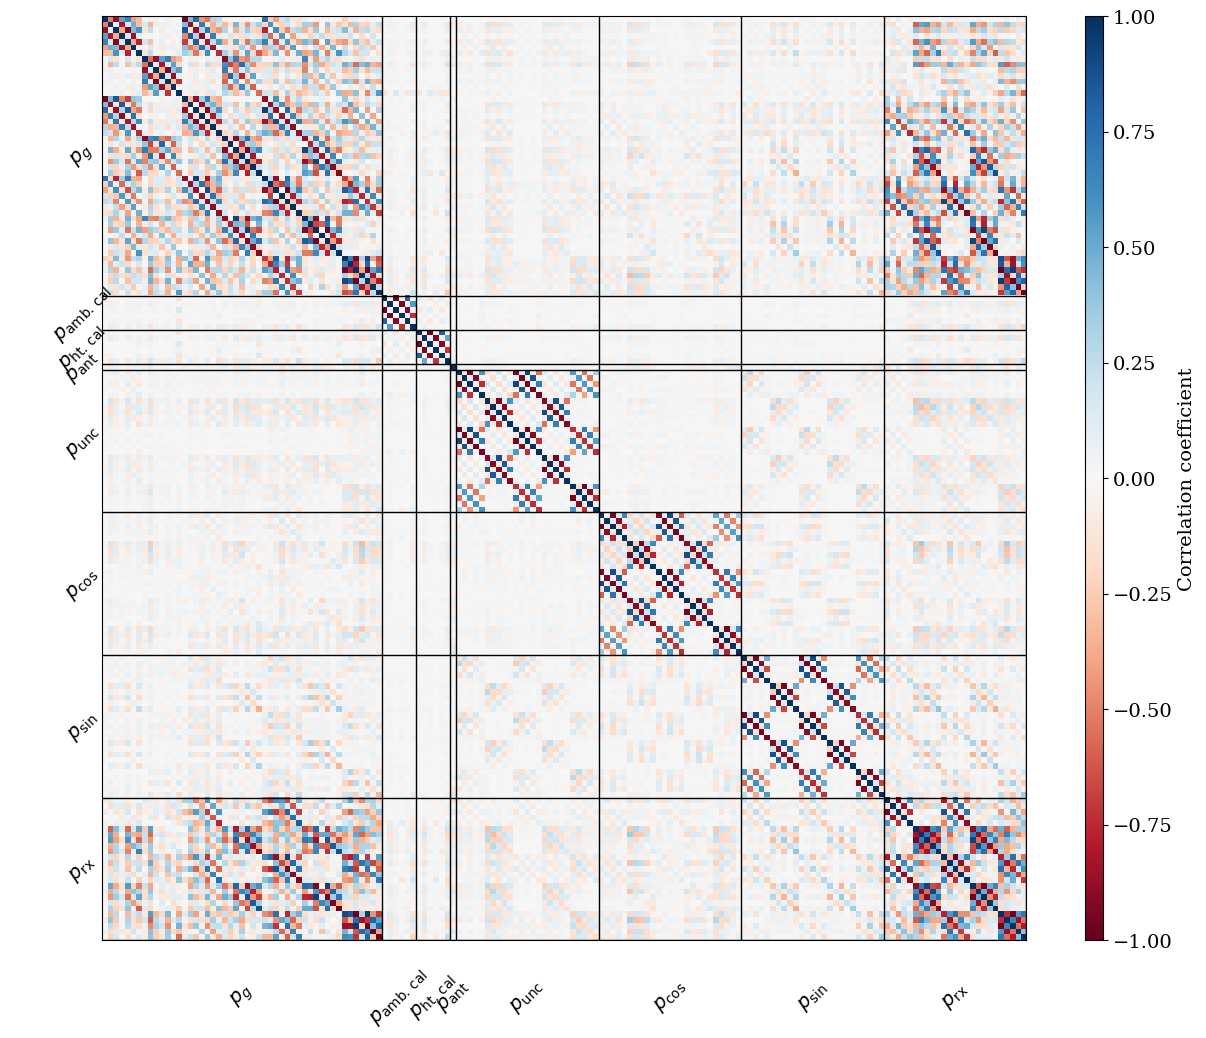

array([[ 1.        , -0.49007761, -0.86535095, ..., -0.00525042,
         0.05995617,  0.01588972],
       [-0.49007761,  1.        ,  0.08628862, ...,  0.25170675,
        -0.20109227, -0.22039103],
       [-0.86535095,  0.08628862,  1.        , ..., -0.20478723,
         0.1250012 ,  0.16014108],
       ...,
       [-0.00525042,  0.25170675, -0.20478723, ...,  1.        ,
        -0.54074383, -0.79681187],
       [ 0.05995617, -0.20109227,  0.1250012 , ..., -0.54074383,
         1.        ,  0.40873055],
       [ 0.01588972, -0.22039103,  0.16014108, ..., -0.79681187,
         0.40873055,  1.        ]], shape=(162, 162))

In [262]:
#
def plot_corr_coeff_all(
        param_dict,
        calibrator_slice_dict,
        ant_noise_wave_slice_dict,
        nw_slice_dict,
        statistic="correlation",
        labels=None,
        cmap="RdBu",
        boundary_lw=1,
        figsize=(10,8),
        fontsize=14
):
    from matplotlib.patches import Rectangle
    gain_chains = param_dict['all_p_gain']
    cal_chains = param_dict['all_p_cal_src']
    ant_nw_chains = param_dict['all_p_ant_nw']

    combined_chains, combined_slice_dict = concat_and_index_operators([gain_chains, cal_chains, ant_nw_chains],
                                                                      label_list=['p_gain', 'p_cal', 'p_antnw'])

    # gain_indices
    gain_indices = combined_slice_dict['p_gain']
    cal_indices = combined_slice_dict['p_cal']
    antnw_indices = combined_slice_dict['p_antnw']

    # calibrators
    ambient_cal_indices_s = cal_indices.start + calibrator_slice_dict['ambient'].start
    ambient_cal_indices_e = cal_indices.start + calibrator_slice_dict['ambient'].stop
    heated_cal_indices_s = cal_indices.start + calibrator_slice_dict['heated'].start
    heated_cal_indices_e = cal_indices.stop
    # antenna
    antenna_indices_s = antnw_indices.start + ant_noise_wave_slice_dict['antenna'].start
    antenna_indices_e = antnw_indices.start + ant_noise_wave_slice_dict['noise_wave'].start

    noise_wave_indices_start = antnw_indices.start + ant_noise_wave_slice_dict['noise_wave'].start

    unc_indices_s = noise_wave_indices_start + nw_slice_dict['unc'].start
    unc_indices_e = noise_wave_indices_start + nw_slice_dict['unc'].stop

    cos_indices_s = noise_wave_indices_start + nw_slice_dict['cos'].start
    cos_indices_e = noise_wave_indices_start + nw_slice_dict['cos'].stop

    sin_indices_s = noise_wave_indices_start + nw_slice_dict['sin'].start
    sin_indices_e = noise_wave_indices_start + nw_slice_dict['sin'].stop

    rx_indices_s = noise_wave_indices_start + nw_slice_dict['rx'].start
    rx_indices_e = noise_wave_indices_start + nw_slice_dict['rx'].stop

    # custom ticks to denote boundaries and n_params
    tick_list = np.arange(gain_indices.stop)
    tick_list = np.concatenate((tick_list, np.arange(int(ambient_cal_indices_e-ambient_cal_indices_s))))
    tick_list = np.concatenate((tick_list, np.arange(int(heated_cal_indices_e-heated_cal_indices_s))))
    tick_list = np.concatenate((tick_list, np.arange(int(antenna_indices_e-antenna_indices_s))))
    tick_list = np.concatenate((tick_list, np.arange(int(unc_indices_e-unc_indices_s))))
    tick_list = np.concatenate((tick_list, np.arange(int(cos_indices_e-cos_indices_s))))
    tick_list = np.concatenate((tick_list, np.arange(int(sin_indices_e-sin_indices_s))))
    tick_list = np.concatenate((tick_list, np.arange(int(rx_indices_e-rx_indices_s))))
    # print(tick_list.shape)
    # print(matrix.shape)
    # ...

    print(antenna_indices_s, antenna_indices_e)

    regions = [(gain_indices.start, gain_indices.stop, 'Gains'),
               (cal_indices.start, cal_indices.stop, 'Calibrators'),
               (antnw_indices.start, antnw_indices.stop, 'Ant NW')]


    regions = [(gain_indices.start, gain_indices.stop, r'$p_g$'),
               (ambient_cal_indices_s, ambient_cal_indices_e, r'$p_{\rm amb.\,cal}$'),
               (heated_cal_indices_s, heated_cal_indices_e, r'$p_{\rm ht.\,cal}$'),
               (antenna_indices_s, antenna_indices_e, r'$p_{\rm ant}$'),
               (unc_indices_s, unc_indices_e, r'$p_{\rm unc}$'),
               (cos_indices_s, cos_indices_e, r'$p_{\rm cos}$'),
               (sin_indices_s, sin_indices_e, r'$p_{\rm sin}$'),
               (rx_indices_s, rx_indices_e, r'$p_{\rm rx}$'),
               ]


    print(gain_indices, cal_indices, antnw_indices)

    

    n_params = combined_chains.shape[1]
    matrix = np.corrcoef(combined_chains, rowvar=False)
    print(tick_list.shape)
    print(matrix.shape)
    # matrix = np.ma.masked_where(np.triu(np.ones_like(matrix, dtype=bool), k=1), matrix)
    fig, ax = plt.subplots(figsize=figsize)
    vmin, vmax = -1, 1
    colorbar_label = "Correlation coefficient"
    image = ax.imshow(matrix, origin="upper", cmap=cmap, vmin=vmin, vmax=vmax)
    cbar = fig.colorbar(image, ax=ax, label=colorbar_label, aspect=50, location='right')
    cbar.set_label(colorbar_label, fontsize=fontsize)
    
    cbar.ax.tick_params(labelsize=fontsize)
    # tick_step = max(1, n_params // 20)
    # tick_positions = np.arange(0, n_params, tick_step)
    # tick_labels = (
    #     [labels[i] for i in tick_positions]
    #     if labels is not None
    #     else [str(i) for i in tick_positions]
    #     )

    zero_marks = np.where(tick_list==0)
    zeroes = np.zeros_like(zero_marks)
    print(zero_marks)

    # ax.set_xticks(np.arange(n_params), tick_list)
    # ax.set_yticks(np.arange(n_params), tick_list)

    # ax.set_xticks(zero_marks, zeroes)
    # ax.set_yticks(zero_marks, zeroes)


    ax.set_xticks([])
    ax.set_yticks([])

    # ax.set_xlabel("Parameter", fontsize=fontsize)
    # ax.set_ylabel("Parameter", fontsize=fontsize)
    # ax.set_title(f"Parameter {statistic}", fontsize=fontsize)

    for xmin, xmax, label in regions:
        rect = Rectangle(
            (xmin, 0),
            xmax - xmin,
            0,
            transform=ax.get_xaxis_transform(),
            clip_on=False,
            facecolor='white',
            edgecolor='white'
        )

        ax.add_patch(rect)

        ax.text(
            (xmin + xmax) / 2 -0.5, -0.06, label,
            transform=ax.get_xaxis_transform(),
            ha='center', va='center',
            rotation=45,
            fontsize=fontsize
        )

        rect2 = Rectangle(
            (-0.1, xmin-0.5),
            0.05,
            xmax-xmin,
            transform=ax.get_yaxis_transform(),
            clip_on=False,
            facecolor='white',
            edgecolor='white'
        )
        ax.add_patch(rect2)

        ax.text(
            -4,
            (xmin + xmax) / 2 -0.5,
            label,
            ha='center', va='center',
            rotation=45,
            fontsize=fontsize
        )

        ax.vlines(x=xmax-0.5, ymin=-0.5, ymax=n_params-0.5, color='k',lw=boundary_lw)
        ax.hlines(y=xmax-0.5, xmax=-0.5, xmin=n_params-0.5, color='k', lw=boundary_lw)
    ax.set_xlim(-0.5, n_params-0.5)
    ax.set_ylim(-0.5, n_params-0.5)

    ax.yaxis.set_inverted(True)
    # ax

    ax.tick_params(
    top=True, labeltop=True,
    bottom=False, labelbottom=False,
    right=True, labelright=True,
    left=False, labelleft=False,)


    plt.show()
    return matrix

plot_corr_coeff_all(param_dict,
                    calibrator_slice_dict,
                    ant_noise_wave_slice_dict,
                    nw_slice_dict,
                    figsize=(15,12))
     
    

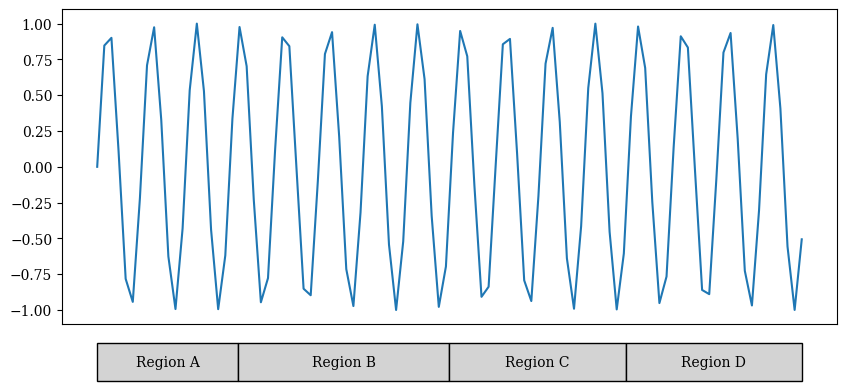

In [263]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(10, 5))

x = np.linspace(0, 100, 100)
y = np.sin(x)
ax.plot(x, y)

regions = [
    (0, 20, 'Region A'),
    (20, 50, 'Region B'),
    (50, 75, 'Region C'),
    (75, 100, 'Region D')
]

for xmin, xmax, label in regions:

    rect = Rectangle(
        (xmin, -0.18),
        xmax - xmin,
        0.12,
        transform=ax.get_xaxis_transform(),
        clip_on=False,
        facecolor='lightgrey',
        edgecolor='black'
    )

    ax.add_patch(rect)

    ax.text(
        (xmin + xmax) / 2, -0.12, label,
        transform=ax.get_xaxis_transform(),
        ha='center', va='center'
    )

ax.set_xticks([])
plt.subplots_adjust(bottom=0.25)
plt.show()